# 07D — Pre-draft athletic fingerprint scorecard

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author.

**Question (RQ6).** Which Combine measurements can already be turned into honest, position-relative, uncertainty-aware descriptive profiles?

**What this is not.** Not a prediction of NFL movement or performance: Milestone 06 established no incremental NFL value for any tracked or learned Combine representation. There is no overall athleticism score, no draft-value or bust label, no injury score, no coaching prescription. NFL data are not an input of any section; an optional, clearly separate panel shows *observed* NFL movement after the fact.

| Section of the card | Inputs | Shown as |
|---|---|---|
| A · Speed Capacity | official forty (headline), official 10-yard split, tracked top speed p95 (components, **not averaged in**) | position percentile + interval |
| B · Speed Development | tracked time 4 → 8 yd/s, only where recorded and supported by the position | position percentile + interval, or *not available* |
| C · Movement Fingerprint | frozen TCN-B representation (fold encoders of 06B; none is trained here) | who he moves like, how stable that is — no rating |
| D · Evidence Confidence | attempts, recording window, sensor noise, repeatability, reference size, seed stability | a tier about the **recording**, kept apart from ability |

**Prerequisite.** Notebooks 00–04A and 06A–06B executed in the same `RUN_MODE` (06C adds the seed-replicate encoders; 07A adds the optional NFL panel). No PyTorch.

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'            # 'smoke' | 'full' — must match notebooks 00–06
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run (seconds to a minute)
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '07D.1'
BOOTSTRAP_ITERATIONS = 1000   # draws per percentile interval (measurement error × reference resampling)
NUM_WORKERS = 0               # interface parity: single-process NumPy

REFERENCE_COHORTS = None      # eligible Combine draft years, e.g. (2023, 2024, 2025); None = every cohort on disk
POSITION_GROUPS = ('DB', 'DL', 'OL', 'TE', 'WR')
QUALITY_THRESHOLDS = {'min_reference': 30,              # athletes of a position before a percentile is shown
                      'min_repeat': 20,                 # athletes with a repeat before measurement error is estimated
                      'available_reliability': 0.70,    # reliability of the athlete value: at or above → available
                      'experimental_reliability': 0.50, # between the two → experimental; below → unavailable
                      'require_signal_ok': True}        # tracked features use attempts without a signal-quality flag only
PROFILE_ATHLETES = 'auto'     # 'auto' = the athletes of the first pre-declared cases · or a list of nfl_id
N_NEIGHBORS = 5
OFFICIAL_CALIPER = (0.05, 0.03)   # |Δ forty| s, |Δ 10-yard| s for 'similar official time' neighbours
CASES_PER_TYPE = 2
SHOW_NFL_PANEL = True         # separate, labelled 'observed in the NFL' box on a card when 07A outputs exist

## 0. Setup and pre-draft inputs

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import context_outcomes as co
from nflbdb.research.advanced_movement import context_reliability as cr
from nflbdb.research.advanced_movement import context_validation as cv
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement.artifacts import MissingArtifactError, ScoringStore
from nflbdb.research.advanced_movement.scoring import NFL_PREDICTIVE_STATUS
from nflbdb.research.advanced_movement.scoring import figures as sf
from nflbdb.research.advanced_movement.scoring import fingerprint as fg
from nflbdb.research.advanced_movement.scoring import percentiles as pc
from nflbdb.research.advanced_movement.scoring import scorecards as sc
from nflbdb.research.advanced_movement.scoring import uncertainty as un

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
Q = dict(QUALITY_THRESHOLDS)
if controls.smoke:
    Q.update(min_reference=5, min_repeat=3)
ref = pc.ReferenceSpec(cohorts=None if REFERENCE_COHORTS is None else tuple(int(c) for c in REFERENCE_COHORTS), positions=tuple(POSITION_GROUPS),
                       min_reference=Q['min_reference'], min_repeat=Q['min_repeat'], available_reliability=Q['available_reliability'],
                       experimental_reliability=Q['experimental_reliability'])
N_DRAWS = 200 if controls.smoke else BOOTSTRAP_ITERATIONS
store = ScoringStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '04A': '04a_feature_characteristic_atlas.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb', '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb',
      '06C': '06c_transfer_robustness_and_scouting_insights.ipynb', '07A': '07a_nfl_outcome_context_decomposition.ipynb'}
PROV = {'notebook': '07d_athletic_fingerprint_scorecard.ipynb', 'experiment_version': EXPERIMENT_VERSION, 'seed': controls.seed, 'reference': ref.params(),
        'quality': Q}
save = lambda df, contract: store.write(df, contract, '07D', PROV) if controls.save_tables else df

# ---- pre-draft inputs only: Combine registry, official results, tracked attempts, frozen representations
athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
frames = up.require(seq.SEQ_FRAMES, NB['01'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
folds = T.require(tr.FOLDS, NB['06A'])
names = T.require(tr.COHORT, NB['06A']).select('nfl_id', 'display_name')
rep = T.require_named('transfer_attempt_representations_outer', NB['06B'])            # fold encoders of 06B; none is trained here
try:
    rep_seeds = T.require_named('transfer_attempt_representations_seeds', NB['06C'])
except MissingArtifactError:
    rep_seeds = None
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))

num = lambda c: pl.col(c).cast(pl.Float64, strict=False)
roster = (athletes.filter(pl.col('position_group').is_in(list(POSITION_GROUPS)))
          .select('nfl_id', 'position_group', pl.col('draft_year').cast(pl.Int64), num(pc.FORTY), num(pc.TEN), num('cmb_combine_weight'), num('cmb_combine_height'))
          .join(names, on='nfl_id', how='left').sort('nfl_id'))
sc.assert_no_nfl_columns(roster, 'roster')
IDS = roster['nfl_id'].to_numpy()
POS = roster['position_group'].to_numpy().astype(str)
YEAR = roster['draft_year'].fill_null(-1).to_numpy()
fold_of = dict(zip(folds['nfl_id'].to_list(), folds['outer_fold'].to_list()))
FOLD = np.array([fold_of.get(int(i), -1) for i in IDS], dtype=np.int64)
POSITION = dict(zip(IDS.tolist(), POS.tolist()))
NAME = dict(zip(roster['nfl_id'].to_list(), roster['display_name'].to_list()))

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {roster.height} Combine athletes in {list(POSITION_GROUPS)} · {windows.height} eligible tracked forty attempts · '
                 f'{int((FOLD >= 0).sum())} athletes with a Milestone 06 fold · seed-replicate encoders: {"found" if rep_seeds is not None else "not found (06C)"}'))
display(Markdown(f'> **NFL predictive status of everything below:** {NFL_PREDICTIVE_STATUS}'))

**Run mode: `full`** (FULL) · 510 Combine athletes in ['DB', 'DL', 'OL', 'TE', 'WR'] · 793 eligible tracked forty attempts · 287 athletes with a Milestone 06 fold · seed-replicate encoders: found

> **NFL predictive status of everything below:** DESCRIPTIVE ONLY — not validated as a predictor of NFL movement or performance (Milestone 06: no incremental gain over official Combine testing was established)

In [3]:
# ---- synthetic validation (planted, known answers; no project data). A failure stops the notebook.
validation = cv.run_all(cv.CHECKS_07D)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1):
    display(validation)
cv.assert_all_passed(validation)

check,status,detail
str,str,str
"""percentile_orientation""","""PASS""","""mid-rank percentile, orientation of times against speeds, leave-one-out reference size"""
"""position_reference_isolation""","""PASS""","""percentiles are isolated by position, leave-one-out for reference members, fold-isolated for held-out scoring"""
"""measurement_uncertainty""","""PASS""","""variance components recovered; reliability rises with attempts; interval widens with measurement error; noise-only measure abstains"""
"""fingerprint_neighbor_selection""","""PASS""","""inductive query encoder, same-position neighbours, official-time caliper, repeat stability; no rating is produced"""
"""no_nfl_leakage_and_abstention""","""PASS""","""NFL-named columns are refused; a missing value abstains; evidence tiers follow the stated rule"""


## 1. Reference population and percentile rule

- **Reference set:** Combine athletes of the same position group, of the eligible cohorts, with a recorded value (tracked features: attempts without a signal-quality flag). Its size is printed with every percentile; below `min_reference` no percentile is given.
- **Algorithm:** mid-rank percentile, **oriented** so that 100 is the shortest time / the highest speed. The raw value and unit always stay beside it.
- **Isolation:** an athlete's own value never sets the scale he is scored against (leave-one-out for reference members). `pct_fold_isolated` scores every athlete against the athletes of the *other* Milestone 06 folds only — the check of how a percentile generalises to a prospect outside the reference.
- **Missing:** a missing measurement gives no percentile and a reason. It is never replaced by the position average.
- **Redundancy (section A):** one headline, the official forty. The 10-yard split and tracked top speed are shown beside it and not averaged in — within position they largely repeat the forty.

In [4]:
display(Markdown(pc.REDUNDANCY_POLICY))
usable = windows.filter(pl.col('S2_signal')) if Q['require_signal_ok'] else windows
QUALITY_RULE = ('official: a recorded value · tracked: eligible forty attempts' + (' without a signal-quality flag (S2_signal)' if Q['require_signal_ok'] else ''))
av = attempt_values.filter(pl.col('seq_id').is_in(usable['seq_id'].to_list()) & pl.col('value').is_not_null() & pl.col('value').is_finite())

tables, ref_tables, sensitivity, ATT = [], [], [], {}
for spec in pc.FEATURES:
    if spec.source == 'official':
        value = roster[spec.feature_id].fill_null(np.nan).to_numpy()
        n_att, attempts = np.isfinite(value).astype(np.int64), None
    else:
        a = av.filter(pl.col('feature_id') == spec.feature_id)
        a_id, a_val = a['nfl_id'].to_numpy().astype(np.int64), a['value'].to_numpy().astype(float)
        ids_w, mean_w, n_w = un.attempts_wide(a_val, a_id)
        pos = np.minimum(np.searchsorted(ids_w, IDS), max(ids_w.size - 1, 0))
        has = (ids_w[pos] == IDS) if ids_w.size else np.zeros(IDS.size, dtype=bool)
        value, n_att, attempts = np.where(has, mean_w[pos], np.nan), np.where(has, n_w[pos], 0).astype(np.int64), (a_id, a_val)
        ATT[spec.feature_id] = dict(zip(ids_w.tolist(), n_w.tolist()))
    t = sc.percentile_table(spec, IDS, POS, YEAR, value, n_att, np.isfinite(value), FOLD, ref, controls.seed, attempts, N_DRAWS)
    tables.append(t)
    in_ref = t['in_reference'].to_numpy()
    ref_tables.append(pc.reference_table(value, POS, in_ref, spec))
    sensitivity += [{'feature_id': spec.feature_id, **r} for r in un.cohort_sensitivity(value, POS, YEAR, in_ref, spec.higher_is_better, ref.min_reference)]
pct = pl.concat(tables).with_columns(pl.when(pl.col('draft_year') < 0).then(None).otherwise(pl.col('draft_year')).alias('draft_year'))
reference_tables = pl.concat(ref_tables)
SPEED_PCT = replace(pc.PCT, name='combine_speed_percentiles')
DEV_PCT = replace(pc.PCT, name='combine_speed_development_percentiles')
speed_pct = save(pct.filter(pl.col('section') == 'speed_capacity'), SPEED_PCT)
dev_pct = save(pct.filter(pl.col('section') == 'speed_development'), DEV_PCT)

with pl.Config(tbl_rows=-1, float_precision=3):
    display(Markdown('**Reference distributions** (what a percentile is relative to)'))
    display(reference_tables)
    display(Markdown('**Availability by feature and position**'))
    display(pct.group_by('feature_id', 'position_group', 'availability').agg(pl.len().alias('athletes'), pl.col('percentile').is_not_null().sum().alias('with_percentile'),
                                                                             pl.col('reliability').median().alias('median_reliability'), pl.col('note').first())
            .sort('feature_id', 'position_group', 'availability'))
    display(Markdown('**Cohort sensitivity** — how far percentiles move when ONE draft cohort is the reference instead of all (percentile points)'))
    display(pl.DataFrame(sensitivity) if sensitivity else Markdown('_not enough athletes per cohort_'))
    iso = pct.filter(pl.col('percentile').is_not_null() & pl.col('pct_fold_isolated').is_not_null()).group_by('feature_id').agg(
        pl.len().alias('athletes'), (pl.col('percentile') - pl.col('pct_fold_isolated')).abs().mean().alias('mean_abs_difference'),
        (pl.col('percentile') - pl.col('pct_fold_isolated')).abs().max().alias('max_abs_difference'))
    display(Markdown('**Reference isolation** — leave-one-out percentile against the percentile on a scale fitted without the athlete\'s fold (percentile points)'))
    display(iso.sort('feature_id'))

Speed Capacity has ONE headline: the official forty percentile. The 10-yard split and the tracked top speed are shown beside it as components and are NOT averaged into it: within position they are strongly correlated with the forty (tracked top speed |ρ| ≈ 0.89, Milestone 04), so adding them would count the same quality several times. Their spread (`speed_agreement`) is reported instead: a large spread says the three measurements disagree about this athlete.

16:02:01 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_speed_percentiles: 1,530 rows → warehouse/gold/advanced_movement/scoring/combine_speed_percentiles.parquet
16:02:01 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_speed_development_percentiles: 510 rows → warehouse/gold/advanced_movement/scoring/combine_speed_development_percentiles.parquet


**Reference distributions** (what a percentile is relative to)

feature_id,position_group,n_reference,mean,sd,q05,q25,q50,q75,q95,unit,higher_is_better
str,str,i64,f64,f64,f64,f64,f64,f64,f64,str,bool
"""cmb_forty""","""DB""",104,4.492,0.089,4.360,4.438,4.490,4.550,4.628,"""s""",false
"""cmb_forty""","""DL""",94,4.858,0.250,4.503,4.662,4.800,5.088,5.263,"""s""",false
"""cmb_forty""","""OL""",95,5.153,0.142,4.947,5.035,5.150,5.240,5.380,"""s""",false
"""cmb_forty""","""TE""",34,4.702,0.102,4.546,4.640,4.695,4.765,4.873,"""s""",false
"""cmb_forty""","""WR""",97,4.472,0.089,4.340,4.400,4.460,4.540,4.614,"""s""",false
"""cmb_ten_yd_split""","""DB""",104,1.536,0.033,1.490,1.510,1.540,1.552,1.590,"""s""",false
"""cmb_ten_yd_split""","""DL""",94,1.699,0.081,1.597,1.642,1.675,1.768,1.820,"""s""",false
"""cmb_ten_yd_split""","""OL""",96,1.783,0.055,1.710,1.740,1.780,1.820,1.870,"""s""",false
"""cmb_ten_yd_split""","""TE""",34,1.595,0.037,1.550,1.570,1.590,1.610,1.663,"""s""",false


**Availability by feature and position**

feature_id,position_group,availability,athletes,with_percentile,median_reliability,note
str,str,str,u32,u32,f64,str
"""F2.forty.p95_speed""","""DB""","""available""",95,95,0.956,"""reliability of the athlete val…"
"""F2.forty.p95_speed""","""DB""","""unavailable""",27,0,null,"""no value recorded: no percenti…"
"""F2.forty.p95_speed""","""DL""","""available""",93,93,0.988,"""reliability of the athlete val…"
"""F2.forty.p95_speed""","""DL""","""unavailable""",25,0,null,"""no value recorded: no percenti…"
"""F2.forty.p95_speed""","""OL""","""available""",93,93,0.965,"""reliability of the athlete val…"
"""F2.forty.p95_speed""","""OL""","""unavailable""",28,0,null,"""no value recorded: no percenti…"
"""F2.forty.p95_speed""","""TE""","""available""",34,34,0.962,"""reliability of the athlete val…"
"""F2.forty.p95_speed""","""TE""","""unavailable""",8,0,null,"""no value recorded: no percenti…"
"""F2.forty.p95_speed""","""WR""","""available""",86,86,0.935,"""reliability of the athlete val…"


**Cohort sensitivity** — how far percentiles move when ONE draft cohort is the reference instead of all (percentile points)

feature_id,position_group,cohort,n_reference_cohort,n_scored,mean_abs_shift,max_abs_shift
str,str,i64,i64,i64,f64,f64
"""cmb_forty""","""DB""",2023,34,104,8.173,18.382
"""cmb_forty""","""DB""",2024,41,104,1.803,5.347
"""cmb_forty""","""DB""",2025,29,104,9.964,16.810
"""cmb_forty""","""DL""",2023,33,94,7.023,15.458
"""cmb_forty""","""DL""",2024,32,94,3.130,7.680
"""cmb_forty""","""DL""",2025,29,94,5.012,15.059
"""cmb_forty""","""OL""",2023,30,95,5.717,11.053
"""cmb_forty""","""OL""",2024,37,95,3.117,8.677
"""cmb_forty""","""OL""",2025,28,95,3.088,7.763


**Reference isolation** — leave-one-out percentile against the percentile on a scale fitted without the athlete's fold (percentile points)

feature_id,athletes,mean_abs_difference,max_abs_difference
str,u32,f64,f64
"""F2.forty.p95_speed""",251,3.765,11.739
"""F6.forty.time_v4_to_v8_s""",251,3.698,15.985
"""cmb_forty""",267,3.627,12.580
"""cmb_ten_yd_split""",267,2.950,10.570


## 2. Section C — movement fingerprint (similarity, not a rating)

Axes of different fold encoders are not the same axes, so every comparison is made inside **one** encoder: an athlete is compared with the others under the encoder of the fold in which he was held out (that encoder never saw his runs). The outputs are *who he moves like* and *how stable that is*. Being far from everybody is not a quality, and no latent coordinate is given a physical name.

16:02:02 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_fingerprint_neighbors: 3,864 rows → warehouse/gold/advanced_movement/scoring/combine_fingerprint_neighbors.parquet
16:02:02 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_fingerprint_stability: 418 rows → warehouse/gold/advanced_movement/scoring/combine_fingerprint_stability.parquet


**418 athletes with a fingerprint** · inductive: 418 · seed replicates used: ['outer/TCN_s1', 'outer/TCN_s2'] (a replicate equal to the primary seed would show an overlap of 1)

position_group,athletes,with_repeat,mean_self_auc,mean_seed_overlap,mean_random_overlap
str,u32,u32,f64,f64,f64
"""DB""",102,93,0.847,0.456,0.174
"""DL""",93,84,0.924,0.660,0.221
"""OL""",95,84,0.868,0.502,0.186
"""TE""",34,32,0.870,0.768,0.270
"""WR""",94,82,0.826,0.526,0.179


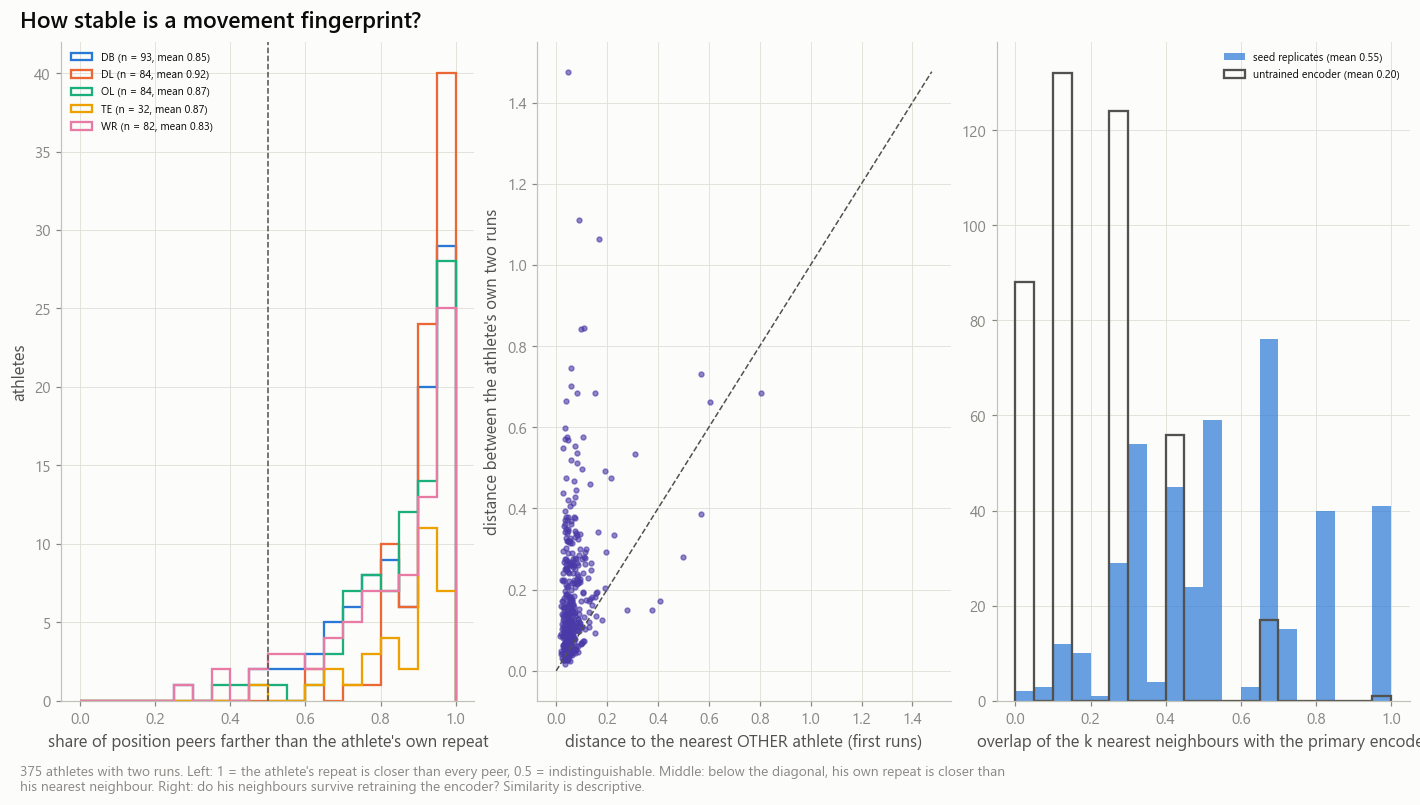

In [5]:
emb = fg.fold_embeddings(rep, ORDER, 'TCN', 'outer')
OFFICIAL = {int(i): (f if f is not None else np.nan, t if t is not None else np.nan) for i, f, t in zip(roster['nfl_id'], roster[pc.FORTY], roster[pc.TEN])}
neighbors = fg.neighbor_table(emb, POSITION, OFFICIAL, N_NEIGHBORS, OFFICIAL_CALIPER)
overlaps = {}
if 'RAND' in rep['family'].unique().to_list():
    overlaps['random'] = fg.neighbor_overlap(neighbors, fg.neighbor_table(fg.fold_embeddings(rep, ORDER, 'RAND', 'outer'), POSITION, None, N_NEIGHBORS))
overlaps['seed'], SEED_REPLICATES = fg.seed_overlaps(neighbors, rep_seeds, ORDER, POSITION, N_NEIGHBORS)
stability = fg.stability_table(emb, POSITION, windows.select('nfl_id', 'attempt_order', 'first_speed', 't_first_s'), overlaps)
neighbors, stability = save(neighbors, fg.NEIGHBORS), save(stability, fg.STABILITY)
dist = fg.distance_lookup(emb)

with pl.Config(tbl_rows=12, float_precision=3):
    display(Markdown(f'**{neighbors["nfl_id"].n_unique()} athletes with a fingerprint** · inductive: {int(stability["inductive"].sum())} · '
                     f'seed replicates used: {SEED_REPLICATES or "none found"} (a replicate equal to the primary seed would show an overlap of 1)'))
    display(stability.group_by('position_group').agg(pl.len().alias('athletes'), pl.col('self_auc').is_not_null().sum().alias('with_repeat'),
                                                    pl.col('self_auc').mean().alias('mean_self_auc'), pl.col('seed_overlap').mean().alias('mean_seed_overlap'),
                                                    pl.col('random_overlap').mean().alias('mean_random_overlap')).sort('position_group'))
store.show(sf.plot_fingerprint_similarity(stability), 'AM07D_06_fingerprint_similarity', {'stability': stability}, publication=True,
           source='transfer_attempt_representations_outer (06B)', n=f'{stability.height} athletes')

## 3. Section D — evidence confidence, and the profiles

The tier describes the **measurement**, never the athlete. Rule (fixed): *high* = at least two attempts, all with usable signal, none starting in motion, speed development measured on at least two, position reference large enough; *medium* = at least one usable attempt with speed development; *low* = tracked but neither; *official only* = no eligible tracked attempt.

16:02:06 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_measurement_confidence: 510 rows → warehouse/gold/advanced_movement/scoring/combine_measurement_confidence.parquet
16:02:06 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_athletic_scorecard_profiles: 510 rows → warehouse/gold/advanced_movement/scoring/combine_athletic_scorecard_profiles.parquet


position_group,low,high,medium,official_only
str,u32,u32,u32,u32
"""DB""",7,73,22,20
"""DL""",null,82,11,25
"""OL""",2,78,15,26
"""TE""",null,30,4,8
"""WR""",8,69,17,13


16:02:06 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_quality_ranking_stability: 8 rows → warehouse/gold/advanced_movement/scoring/combine_quality_ranking_stability.parquet


feature_id,evidence_tier,n_athletes,rank_agreement,ci_lower,ci_upper,mean_abs_percentile_shift
str,str,i64,f64,f64,f64,f64
"""F2.forty.p95_speed""","""ALL""",375,0.918,0.881,0.935,9.271
"""F2.forty.p95_speed""","""high""",332,0.923,0.889,0.940,9.456
"""F2.forty.p95_speed""","""medium""",30,0.946,0.738,0.994,7.929
"""F2.forty.p95_speed""","""low""",13,0.786,0.181,1.000,7.648
"""F6.forty.time_v4_to_v8_s""","""ALL""",375,0.732,0.658,0.799,17.332
"""F6.forty.time_v4_to_v8_s""","""high""",332,0.767,0.684,0.824,16.616
"""F6.forty.time_v4_to_v8_s""","""medium""",30,0.239,-0.208,0.678,24.181
"""F6.forty.time_v4_to_v8_s""","""low""",13,0.643,-0.212,1.000,19.823


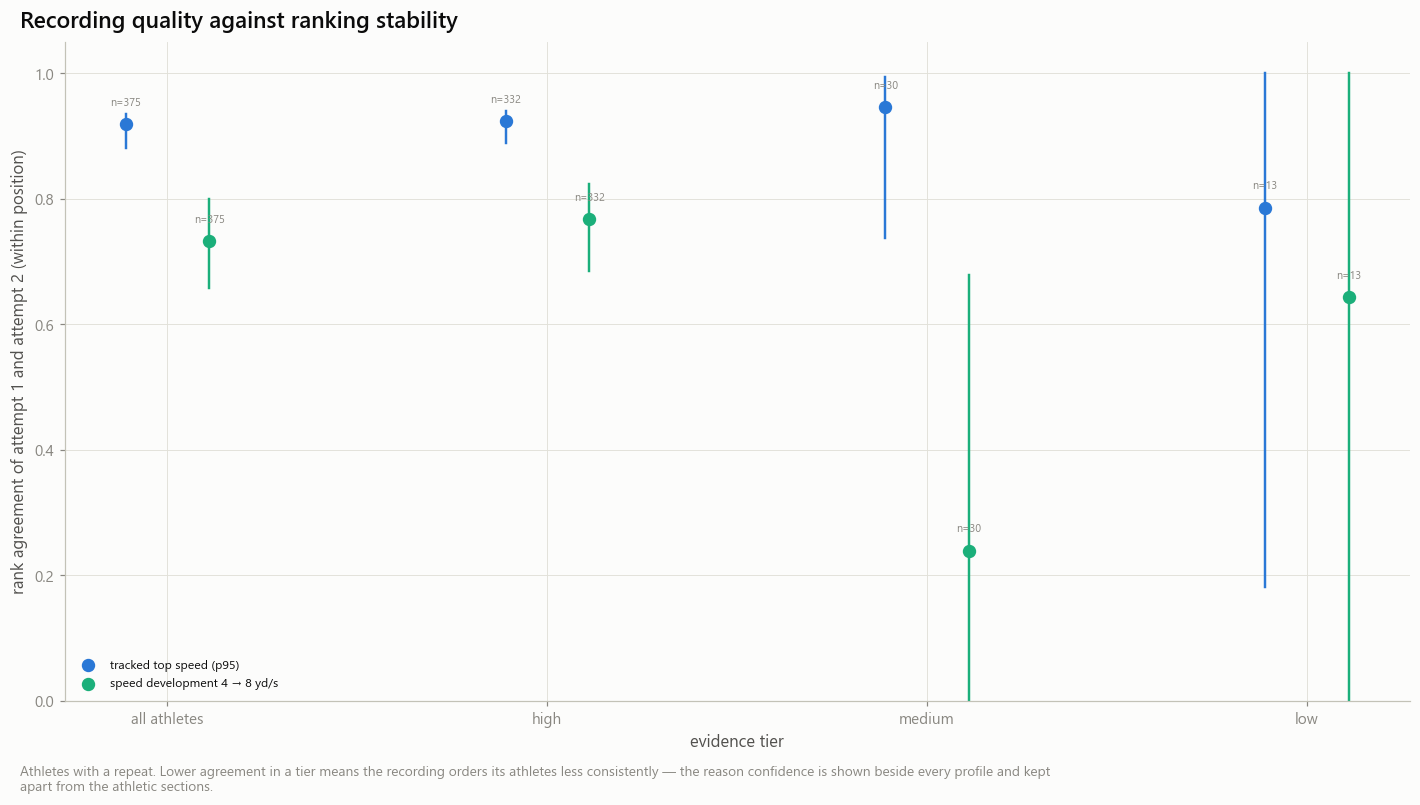

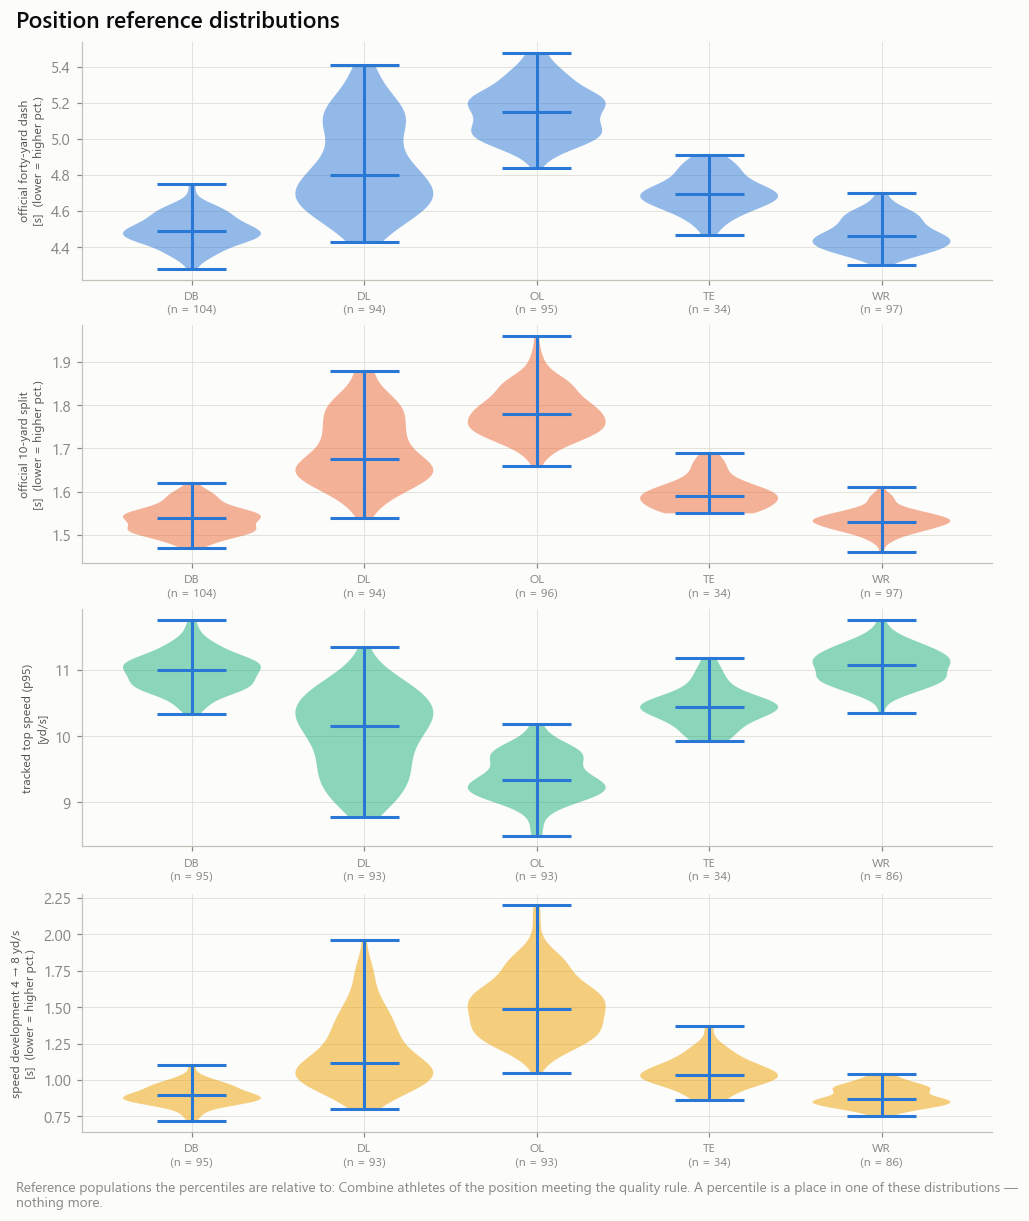

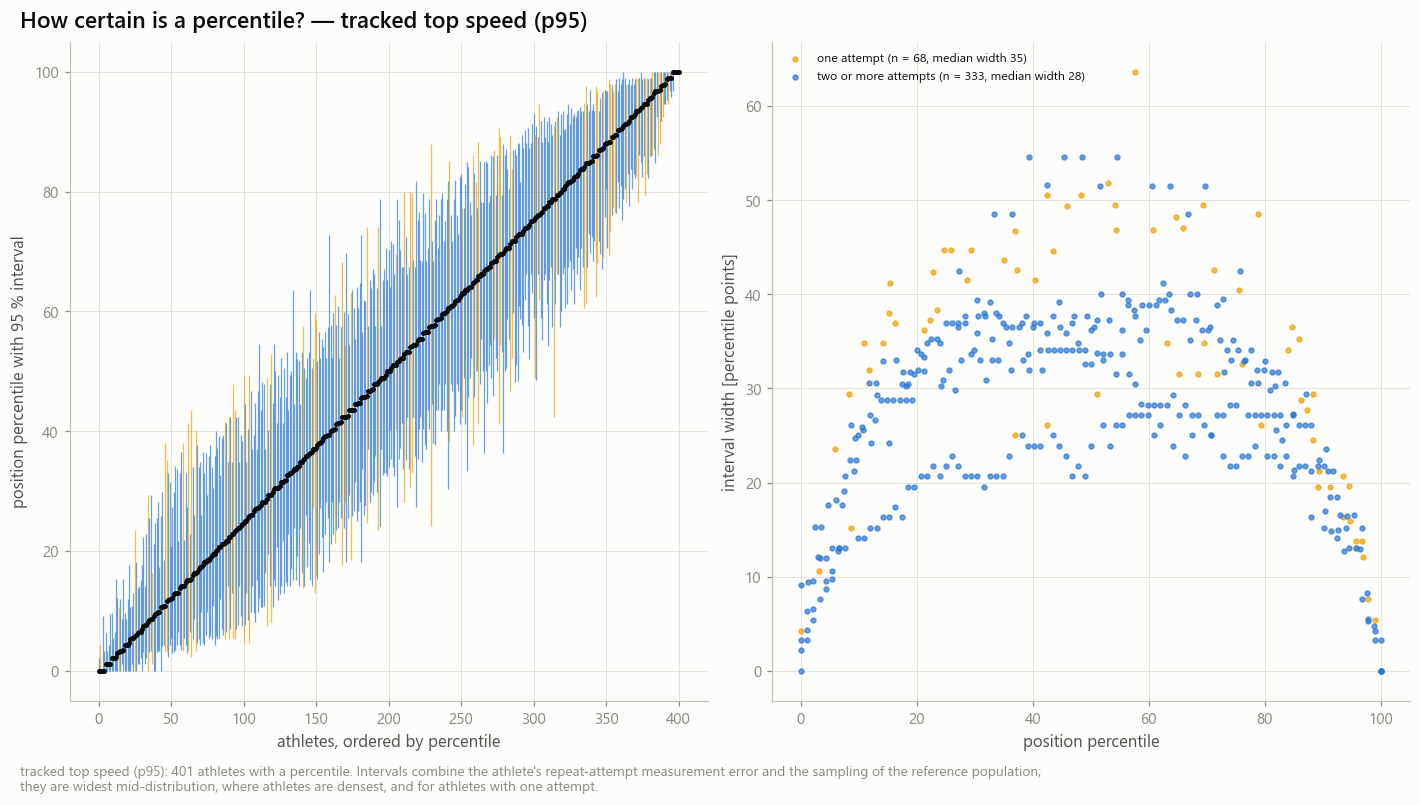

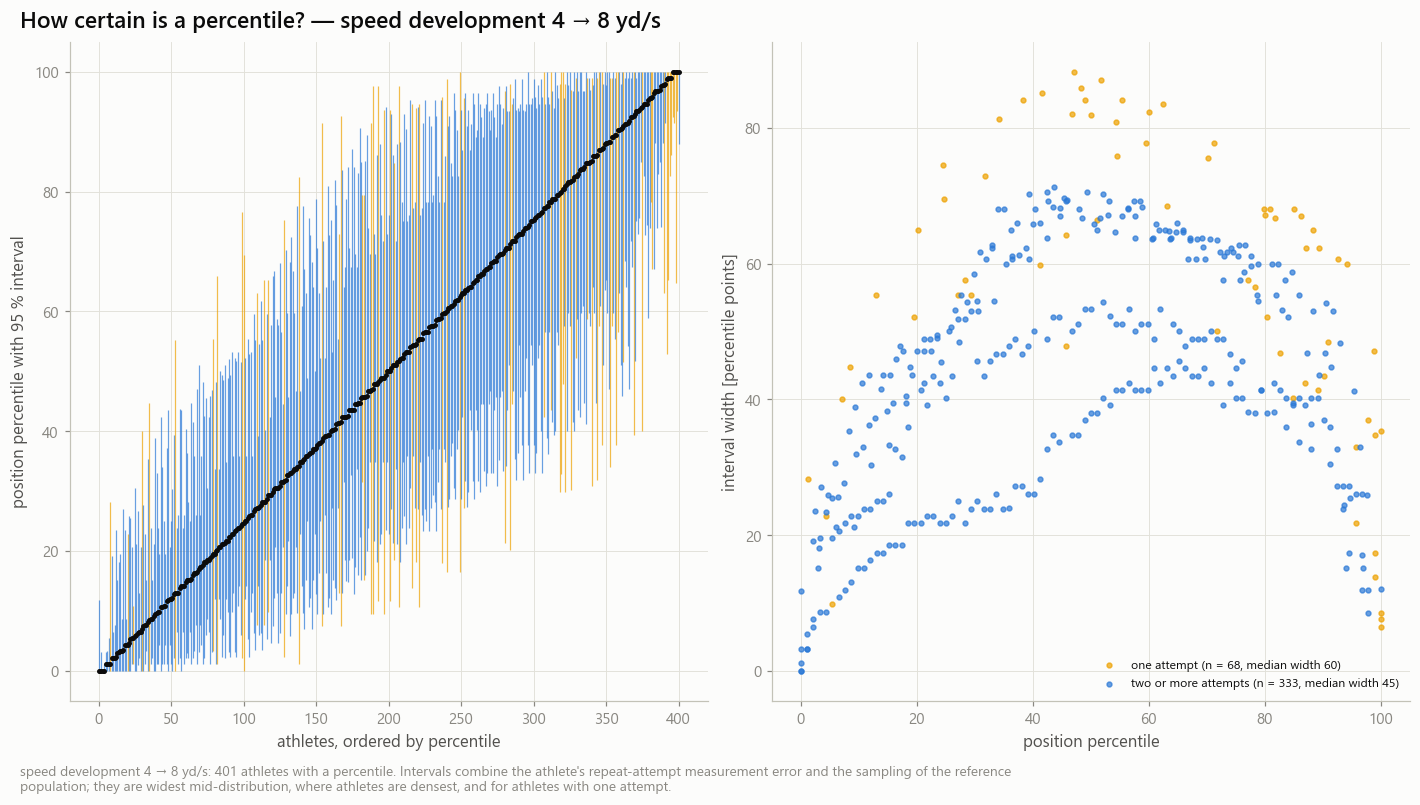

In [6]:
ref_n = {r['position_group']: r['n_reference'] for r in reference_tables.filter(pl.col('feature_id') == pc.FORTY).iter_rows(named=True)}
# ALL eligible attempts go in (not only the clean ones): the tier must see a signal-quality flag to report it
confidence = save(sc.confidence_table(roster, windows, ATT.get(pc.V4_V8, {}), stability, ref_n, ref.min_reference), sc.CONFIDENCE)
profile = save(sc.profile_table(roster, pct, neighbors, confidence), sc.PROFILE)
with pl.Config(tbl_rows=-1):
    display(confidence.group_by('position_group', 'evidence_tier').agg(pl.len().alias('athletes')).pivot(on='evidence_tier', index='position_group', values='athletes').sort('position_group'))

quality = save(sc.quality_stability(attempt_values, windows, confidence, pct, [pc.P95, pc.V4_V8], min(N_DRAWS, 500), controls.seed), sc.STABILITY_BY_QUALITY)
with pl.Config(tbl_rows=-1, float_precision=3):
    display(quality)
store.show(sf.plot_quality_stability(quality), 'AM07D_07_quality_vs_ranking_stability', {'quality': quality}, source='atlas_attempt_features + combine_measurement_confidence',
           n='athletes with a repeat')
store.show(sf.plot_reference_distributions(pct, [f.feature_id for f in pc.FEATURES]), 'AM07D_03_position_percentile_distributions', {'reference': reference_tables},
           publication=True, source='combine percentile tables', n=f'{roster.height} Combine athletes')
for fid in (pc.P95, pc.V4_V8):
    store.show(sf.plot_uncertainty(pct, fid), f'AM07D_05_uncertainty_{fid.split(".")[-1]}', {'percentiles': pct.filter(pl.col('feature_id') == fid)},
               publication=(fid == pc.V4_V8), source='combine percentile tables', n='athletes with a percentile')

## 4. Scouting case studies — chosen by Combine-side rules fixed in advance

Five case types, each with a selection rule that uses official times, tracked Combine measures, the fingerprint and the evidence tier — **nothing from the NFL**. The rule picks the pairs; nobody picks them by looking at what happened later. A case illustrates what a profile shows; it is not evidence of anything in the NFL.

16:02:12 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07D] combine_scorecard_examples: 10 rows → warehouse/gold/advanced_movement/scoring/combine_scorecard_examples.parquet


case,position_group,name_a,name_b,matched_on,contrast,value_a,value_b,contrast_size,fingerprint_distance,criterion
str,str,str,str,str,str,f64,f64,f64,f64,str
"""similar_forty_different_development""","""WR""","""Devaughn Vele""","""Jayden Higgins""","""official_forty, official_ten""","""speed_development_pct""",97.647,9.412,88.235,0.154,"""official forty and 10-yard split within 0.03 s; largest difference in speed-development percentile"""
"""similar_forty_different_development""","""WR""","""Jermaine Burton""","""Elijhah Badger""","""official_forty, official_ten""","""speed_development_pct""",95.294,10.588,84.706,0.485,"""official forty and 10-yard split within 0.03 s; largest difference in speed-development percentile"""
"""similar_top_speed_different_curve""","""DB""","""Trey Dean""","""Cole Bishop""","""top_speed_pct""","""fingerprint distance""",null,null,1.150,1.150,"""tracked top-speed percentile within 5 points; largest fingerprint distance"""
"""similar_top_speed_different_curve""","""DL""","""Byron Young""","""YaYa Diaby""","""top_speed_pct""","""fingerprint distance""",null,null,1.114,1.114,"""tracked top-speed percentile within 5 points; largest fingerprint distance"""
"""repeatable_fingerprint_difference""","""OL""","""Anton Harrison""","""Aireontae Ersery""","""official_forty, official_ten""","""fingerprint distance""",null,null,1.241,1.241,"""official times within 0.03 s, both repeats closer than 90 % of the position; largest fingerprint distance"""
"""repeatable_fingerprint_difference""","""DB""","""Rayuan Lane""","""Hunter Wohler""","""official_forty, official_ten""","""fingerprint distance""",null,null,1.159,1.159,"""official times within 0.03 s, both repeats closer than 90 % of the position; largest fingerprint distance"""
"""physical_agrees_fingerprint_differs""","""OL""","""Caleb Rogers""","""Carson Vinson""","""official_forty, official_ten, speed_development_pct""","""fingerprint distance""",null,null,1.114,1.114,"""official times within 0.03 s and speed-development percentile within 10 points; largest fingerprint distance"""
"""physical_agrees_fingerprint_differs""","""OL""","""Earl Bostick""","""Joshua Gray""","""official_forty, official_ten, speed_development_pct""","""fingerprint distance""",null,null,1.097,1.097,"""official times within 0.03 s and speed-development percentile within 10 points; largest fingerprint distance"""
"""high_versus_low_recording_confidence""","""OL""","""Troy Fautanu""","""Jon Gaines""","""official_forty""","""evidence_tier""",null,null,0.000,0.396,"""same position, official forty within 0.03 s, evidence tier low vs high (closest forty first)"""


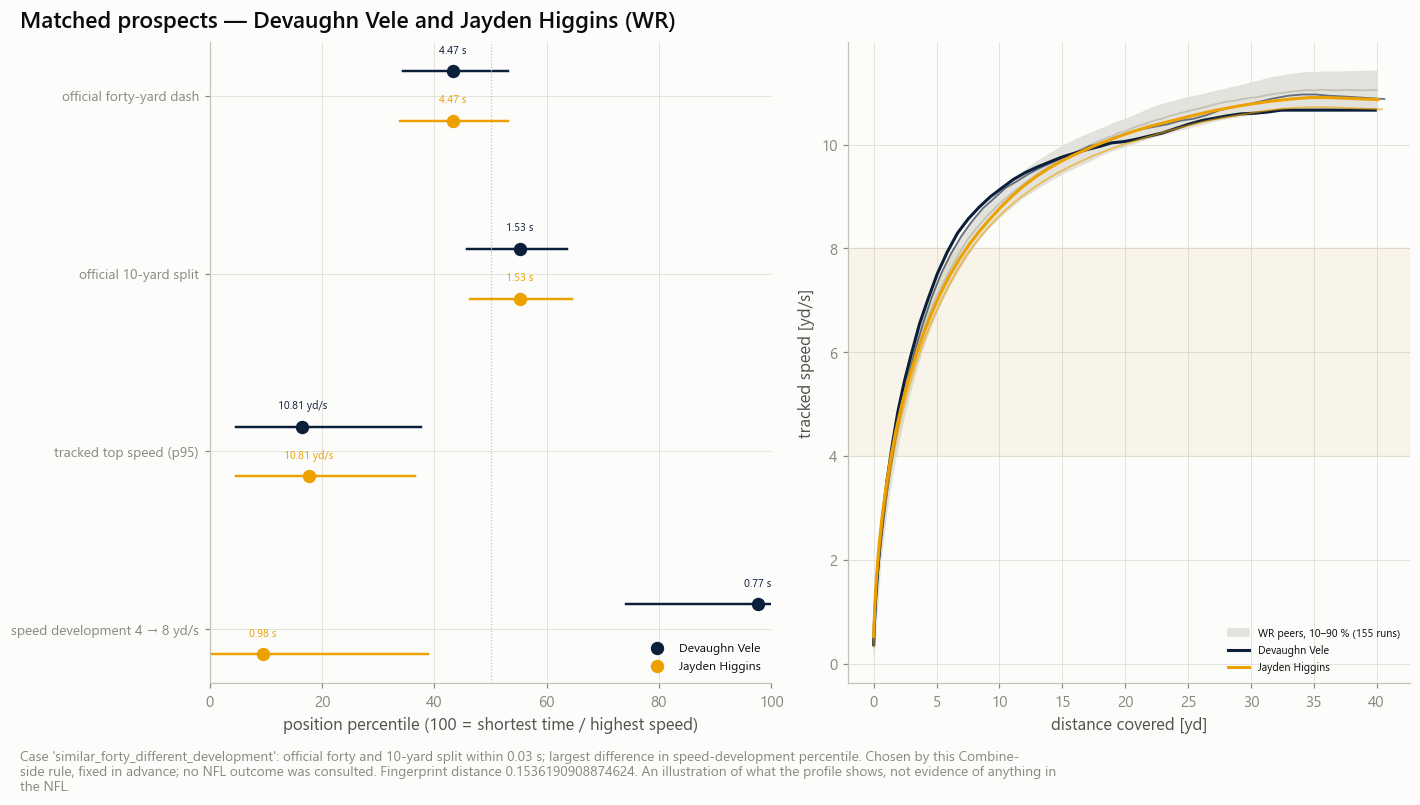

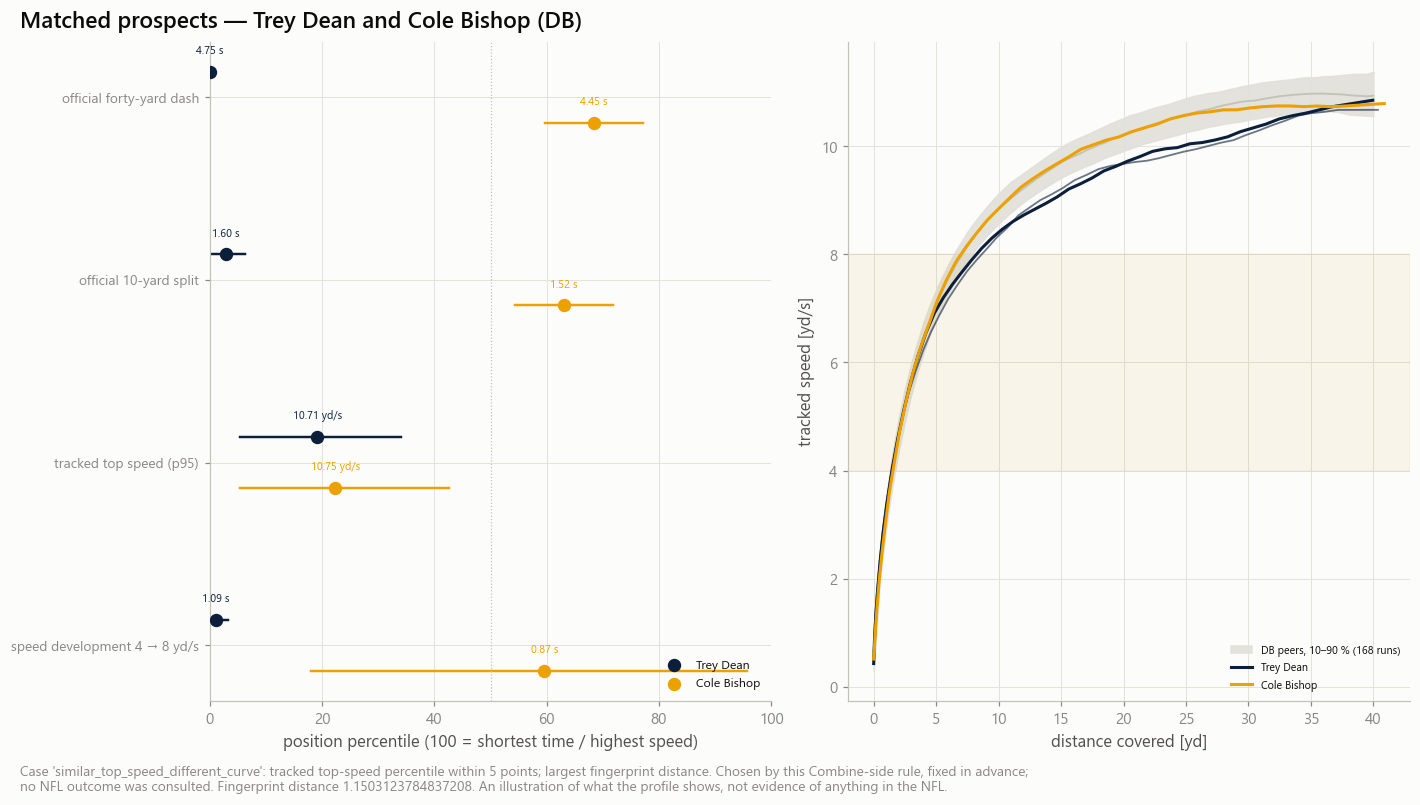

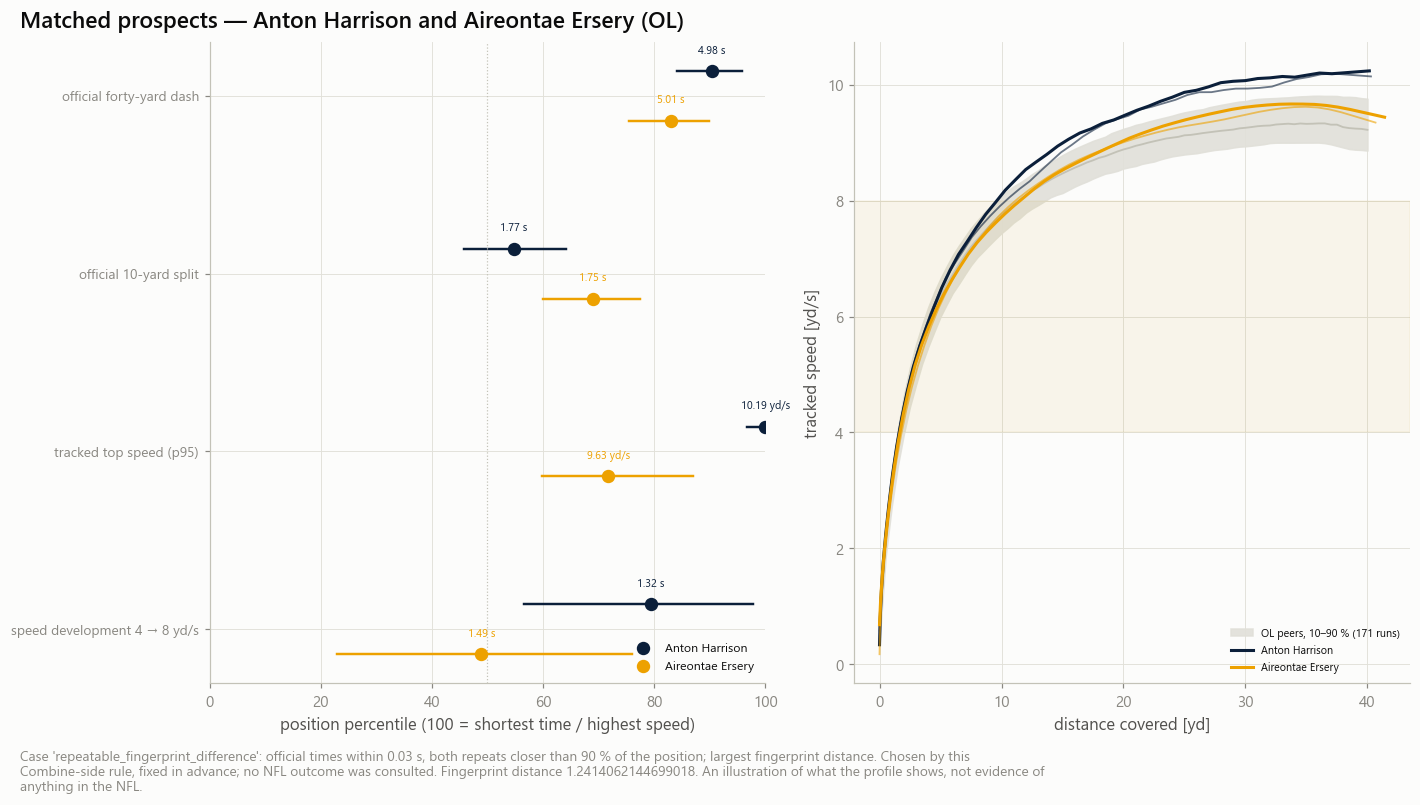

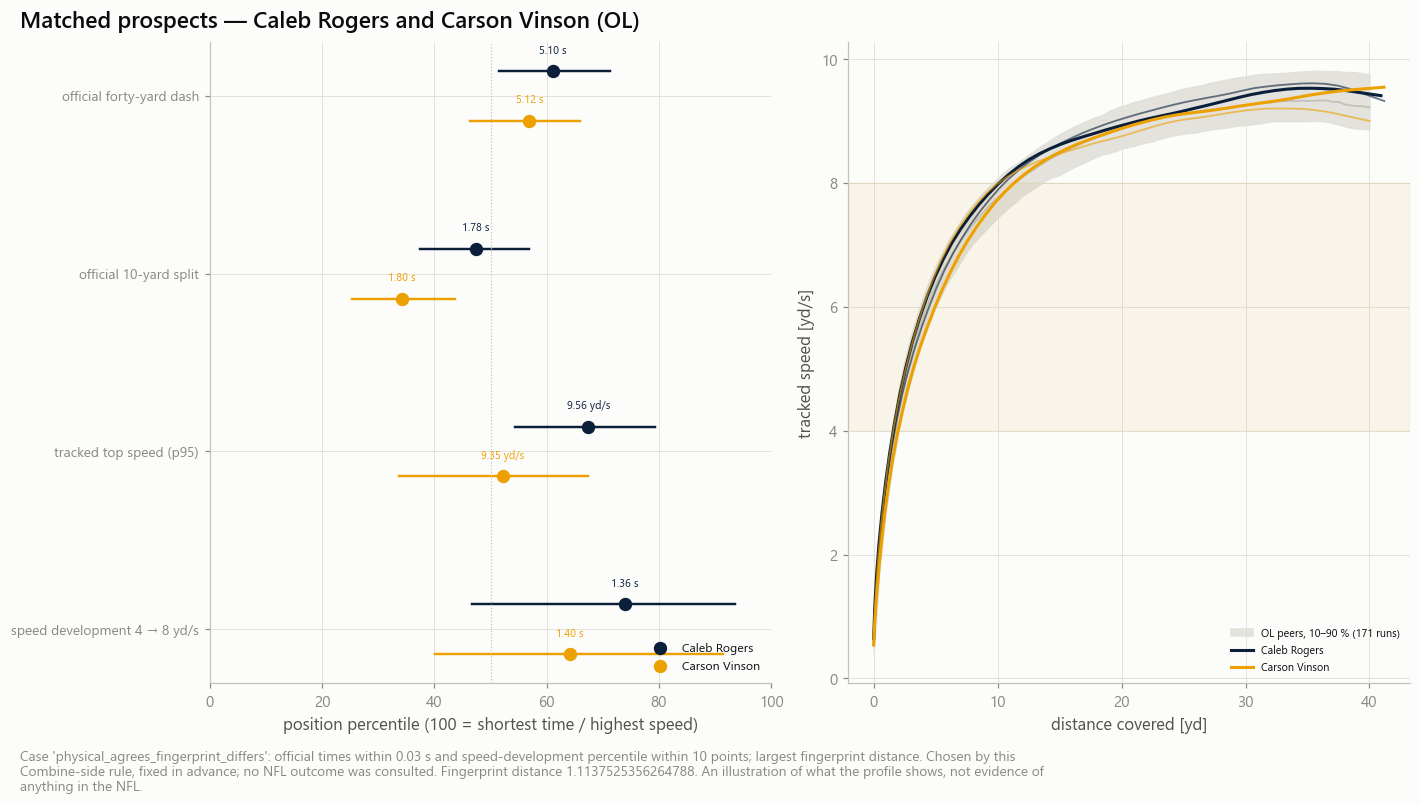

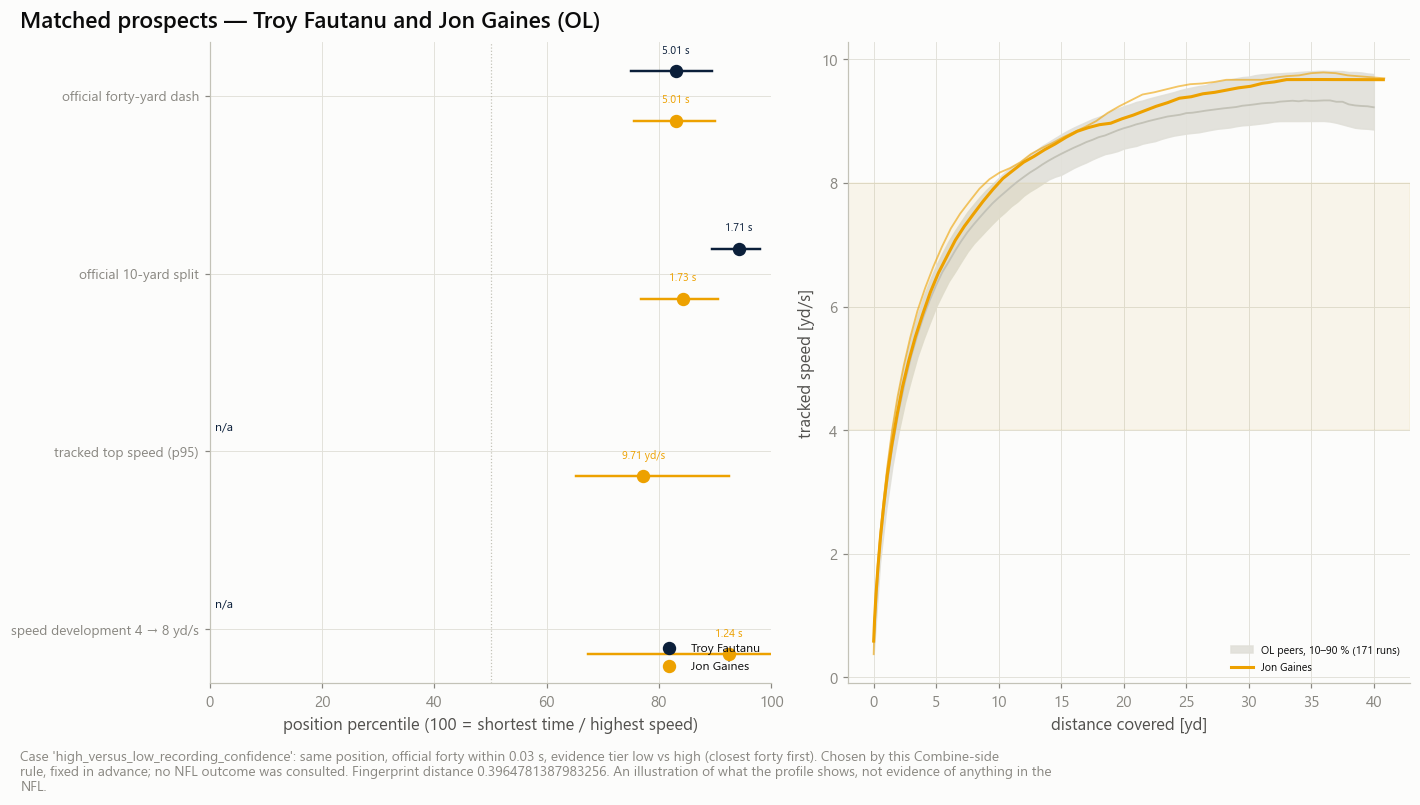

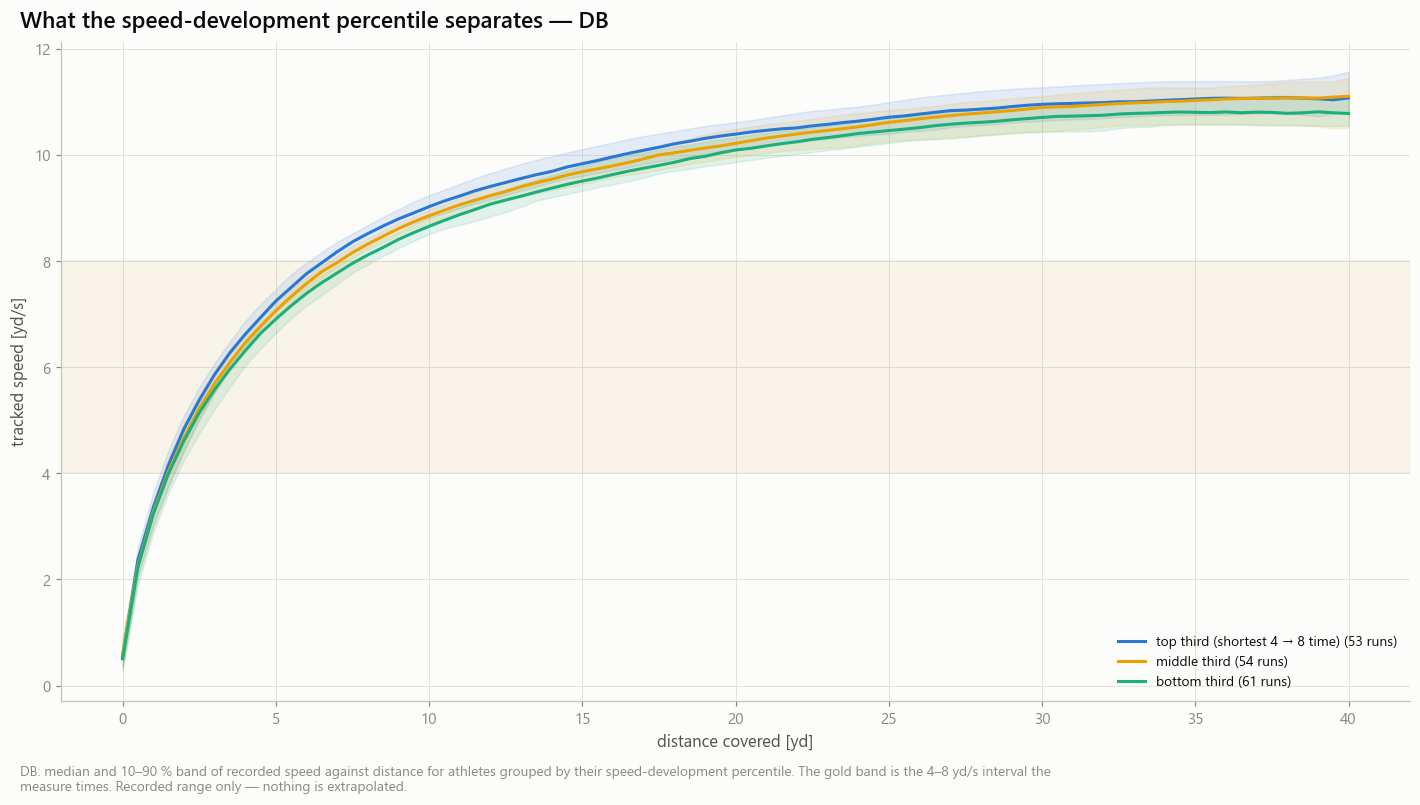

In [7]:
examples = save(sc.case_studies(profile, dist, CASES_PER_TYPE), sc.EXAMPLES)
with pl.Config(tbl_rows=-1, fmt_str_lengths=140, float_precision=3):
    display(examples.select('case', 'position_group', 'name_a', 'name_b', 'matched_on', 'contrast', 'value_a', 'value_b', 'contrast_size', 'fingerprint_distance', 'criterion'))

seqs_of = {int(i): s for i, s in zip(*usable.group_by('nfl_id').agg(pl.col('seq_id')).select('nfl_id', 'seq_id'))}
pos_seqs = {p: usable.filter(pl.col('position_group') == p)['seq_id'].to_list() for p in POSITION_GROUPS}
BANDS = {p: sf.curve_band(frames, s) for p, s in pos_seqs.items() if s}
curves_of = lambda i: sf.athlete_curves(frames, list(seqs_of.get(int(i), [])))

for k, case in enumerate(examples.unique(subset=['case'], keep='first', maintain_order=True).iter_rows(named=True), 1):
    p = case['position_group']
    if p not in BANDS:
        continue
    na, nb = case['name_a'] or str(case['nfl_id_a']), case['name_b'] or str(case['nfl_id_b'])
    store.show(sf.plot_matched_prospects(case, pct, BANDS[p], {na: curves_of(case['nfl_id_a']), nb: curves_of(case['nfl_id_b'])}),
               f'AM07D_02_matched_prospects_{k:02d}_{case["case"]}', {'case': examples.filter(pl.col('case') == case['case'])}, publication=(k == 1),
               source='combine percentile tables + sequence_frames', n='2 athletes (illustration)')

# ---- what the speed-development percentile separates, in recorded curves (largest position group)
dev = profile.filter(pl.col('speed_development_pct').is_not_null())
if dev.height:
    big = dev.group_by('position_group').agg(pl.len().alias('n')).sort('n', descending=True)['position_group'][0]
    g = dev.filter(pl.col('position_group') == big)
    pick = lambda lo, hi: [s for i in g.filter((pl.col('speed_development_pct') >= lo) & (pl.col('speed_development_pct') <= hi))['nfl_id'].to_list() for s in seqs_of.get(int(i), [])]
    groups = {'top third (shortest 4 → 8 time)': sf.curve_band(frames, pick(66.7, 100), 5), 'middle third': sf.curve_band(frames, pick(33.3, 66.7), 5),
              'bottom third': sf.curve_band(frames, pick(0, 33.3), 5)}
    store.show(sf.plot_development_curves(groups, big), 'AM07D_04_speed_development_curves', {'profiles': g.select('nfl_id', 'speed_development_value', 'speed_development_pct')},
               publication=True, source='sequence_frames + combine_speed_development_percentiles', n=f'{g.height} {big} athletes')

## 5. Player scorecards

One card per profiled athlete: official times, the four sections, intervals, reference sizes, what the measurements mean, and the explicit NFL predictive status. Real athlete data only; a section without support says *not available* instead of showing a number.

**Optional post-draft panel.** When 07A outputs exist and `SHOW_NFL_PANEL` is on, a separate box labelled *observed in the NFL* lists the athlete's observed movement. It is read **after** every pre-draft table was written, is not an input of any section, and the difference between a Combine percentile and an NFL observation is **not** "unused potential" — no transfer model has enough evidence to define such a gap.

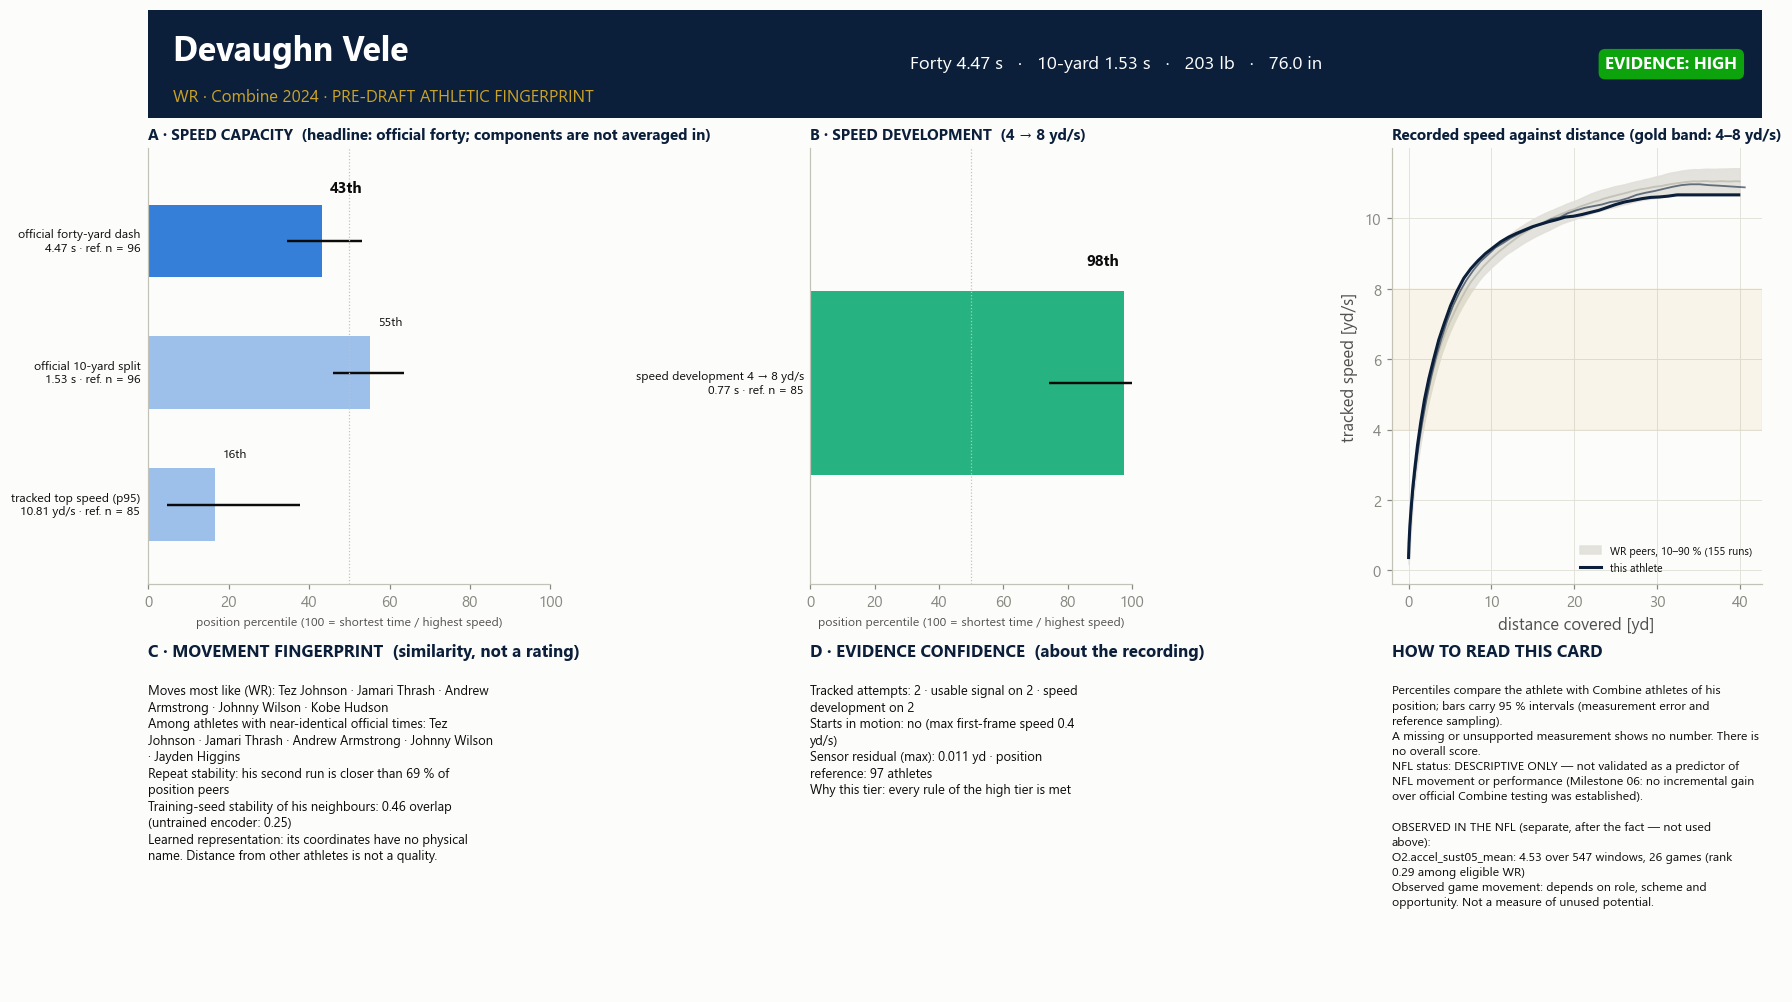

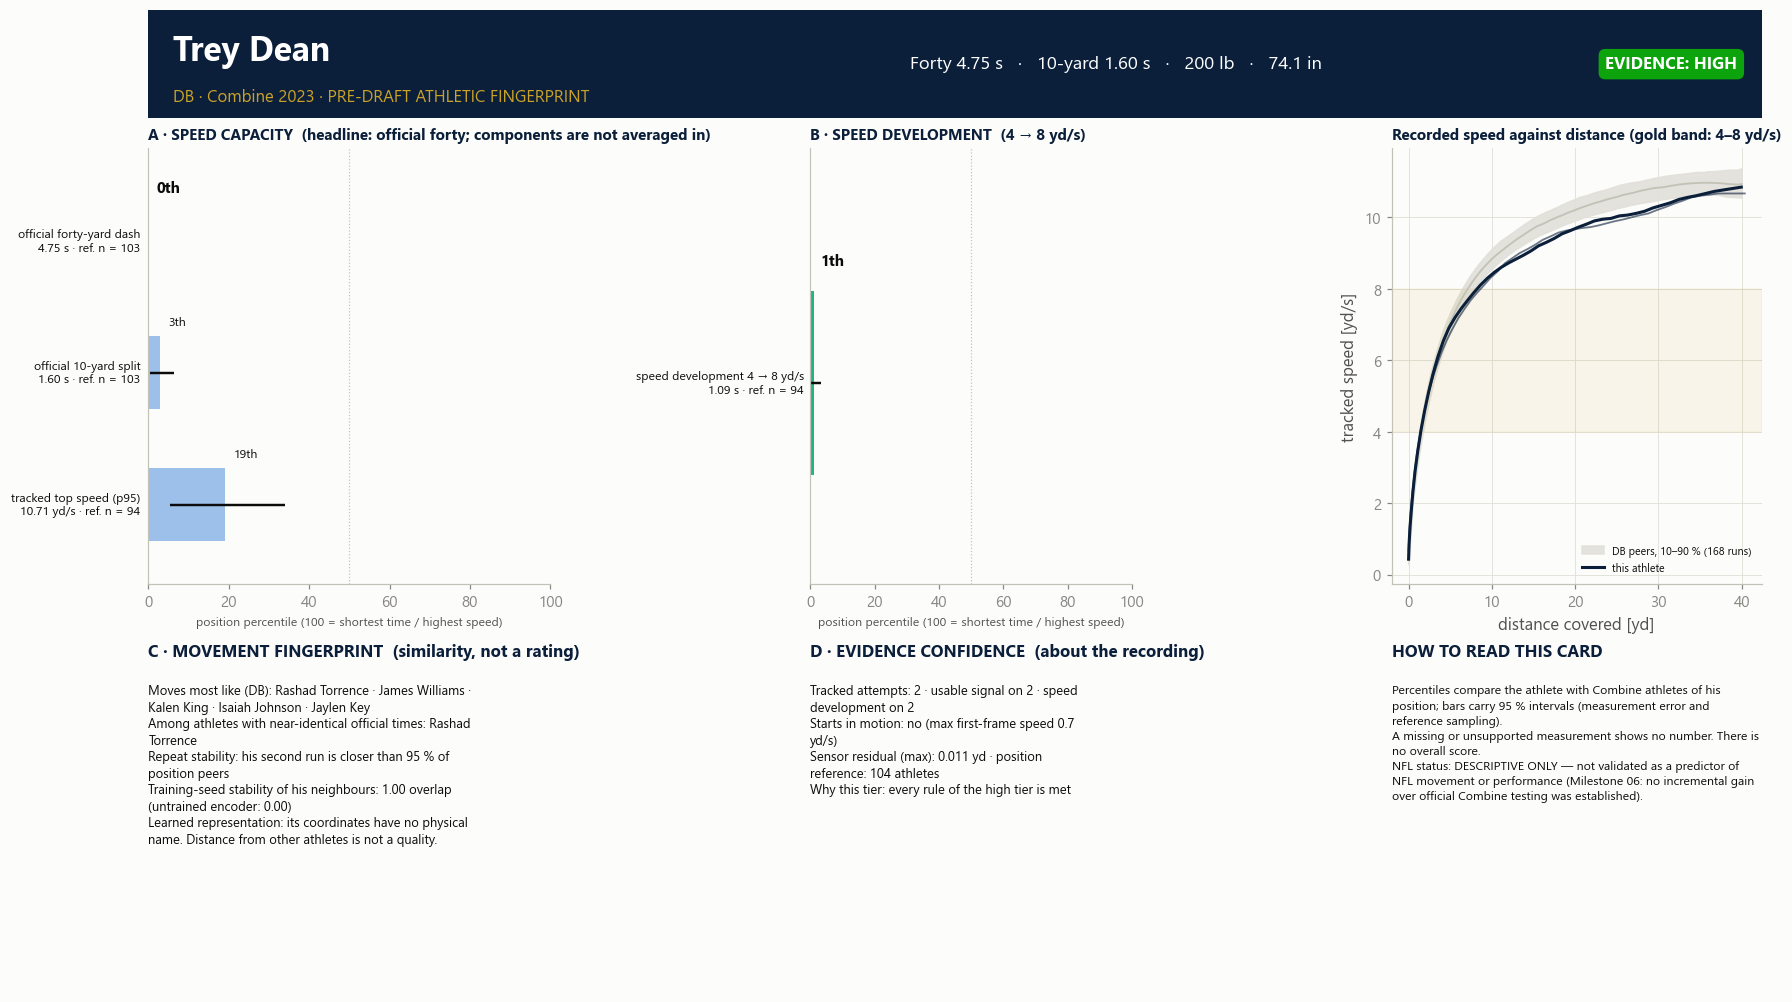

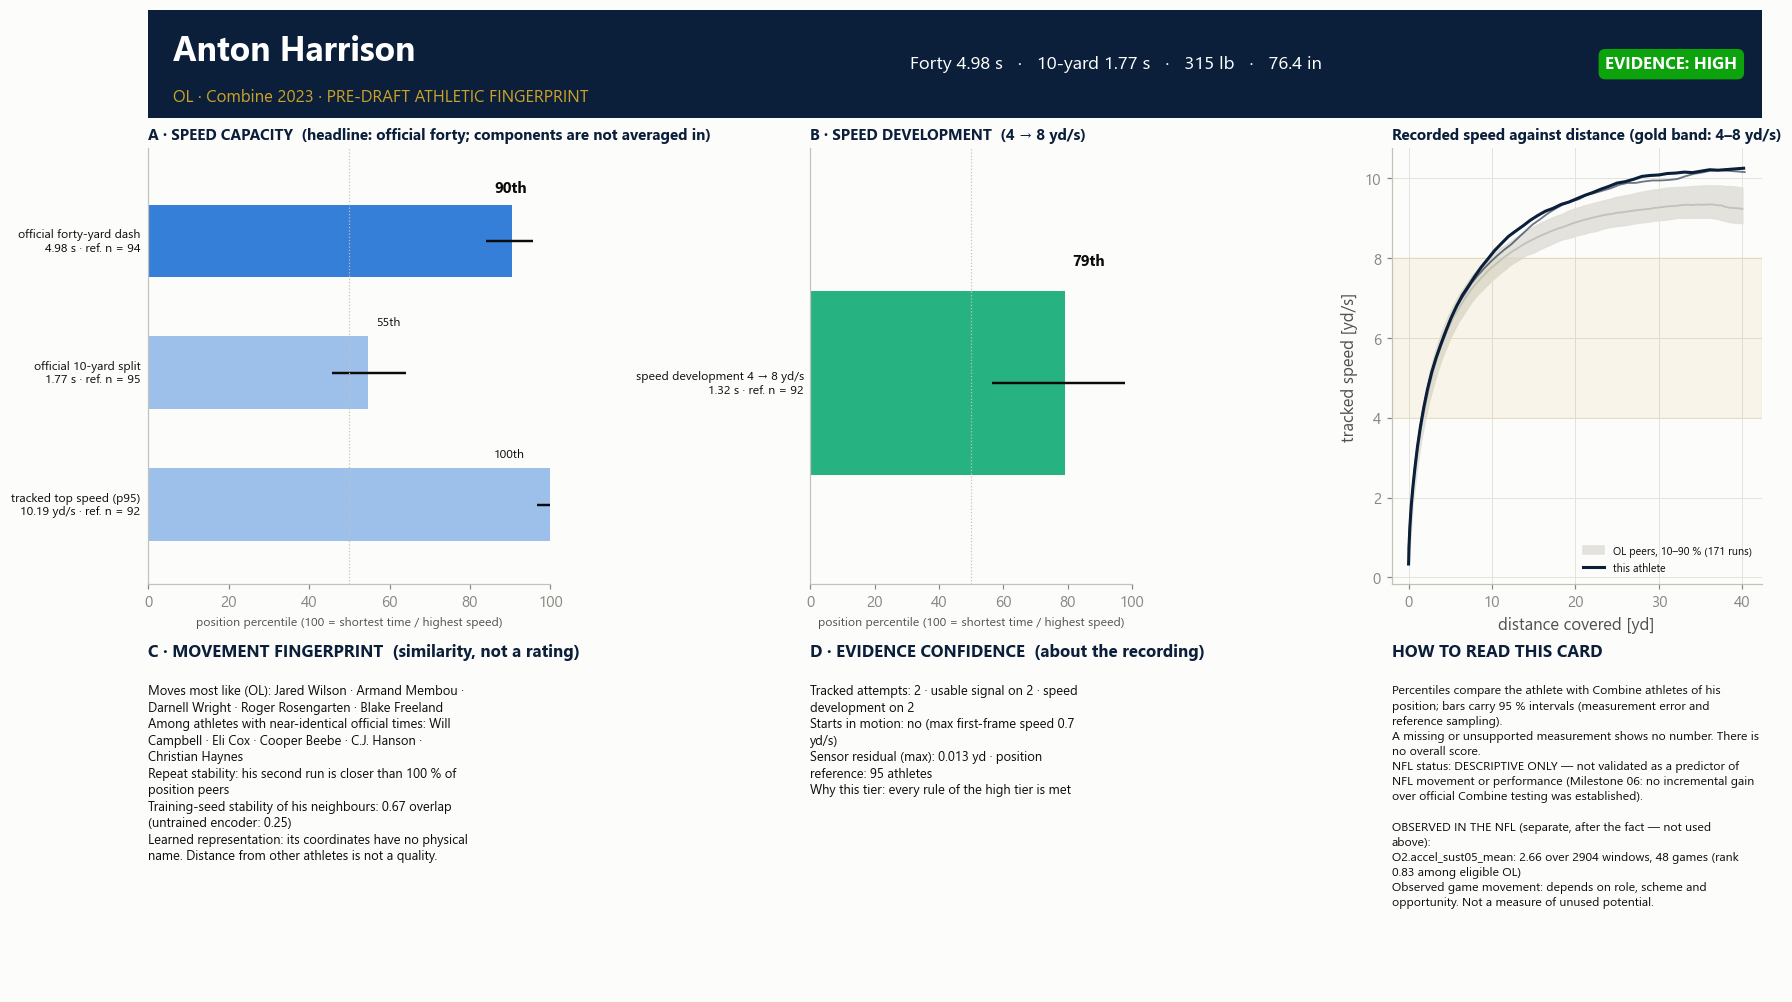

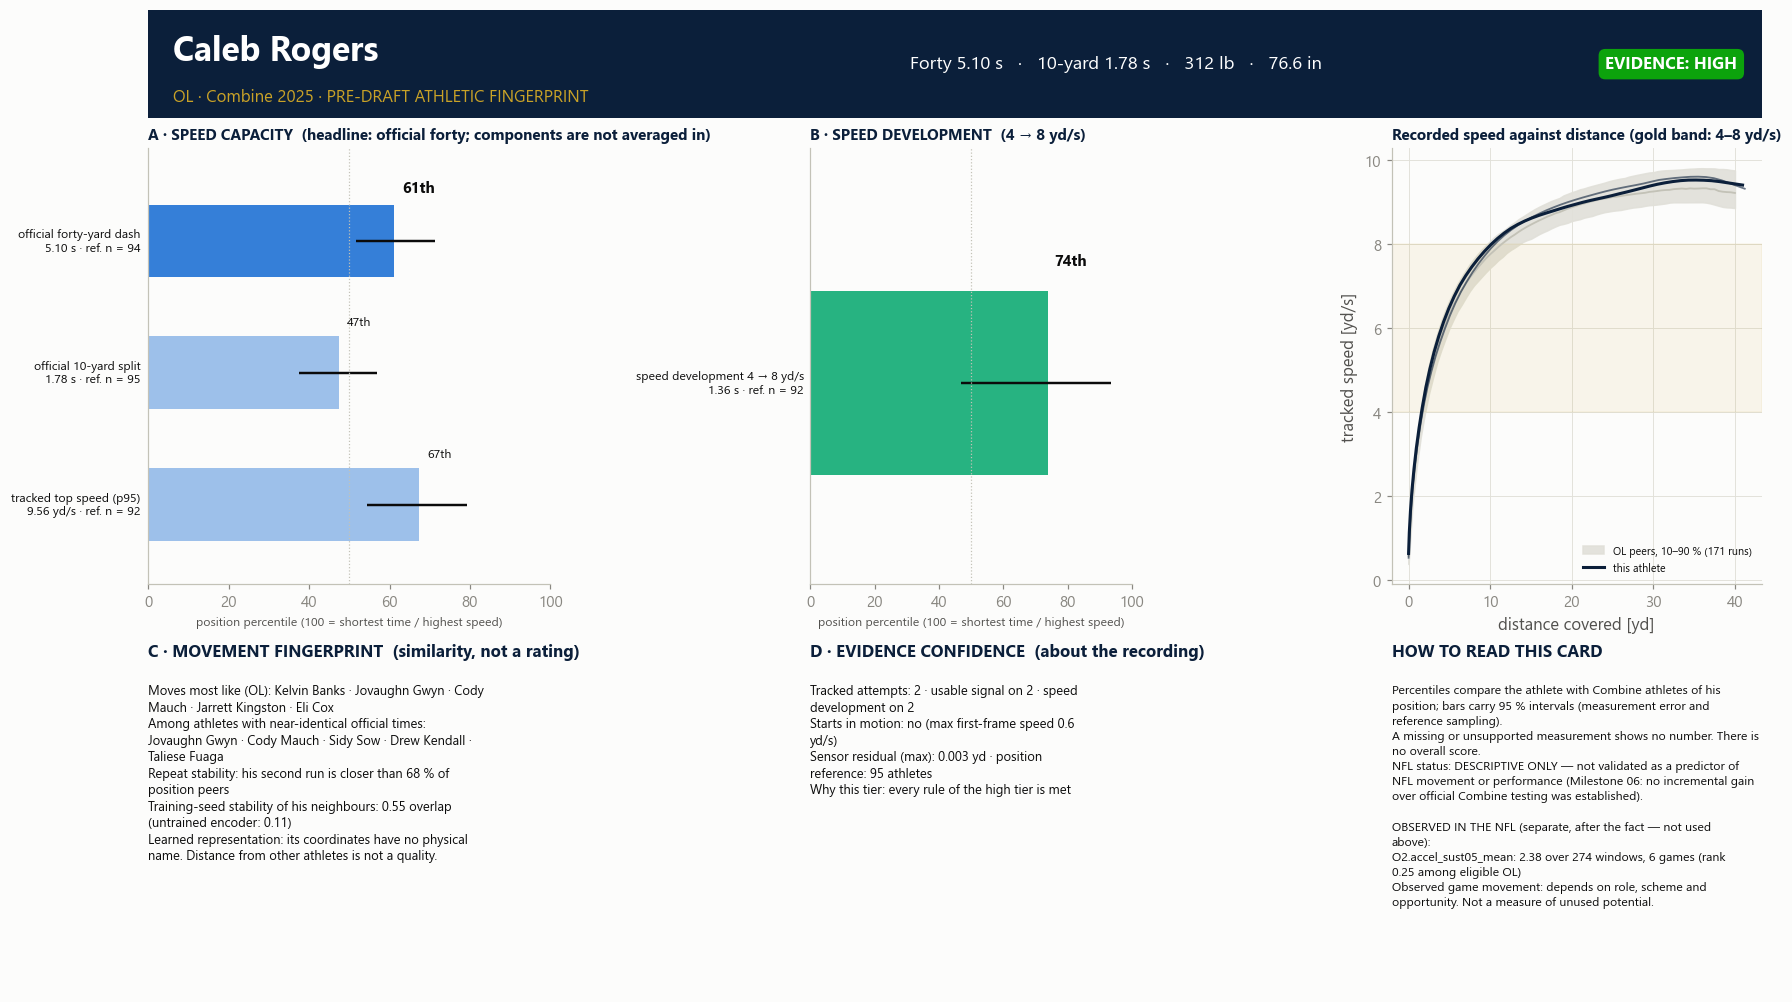

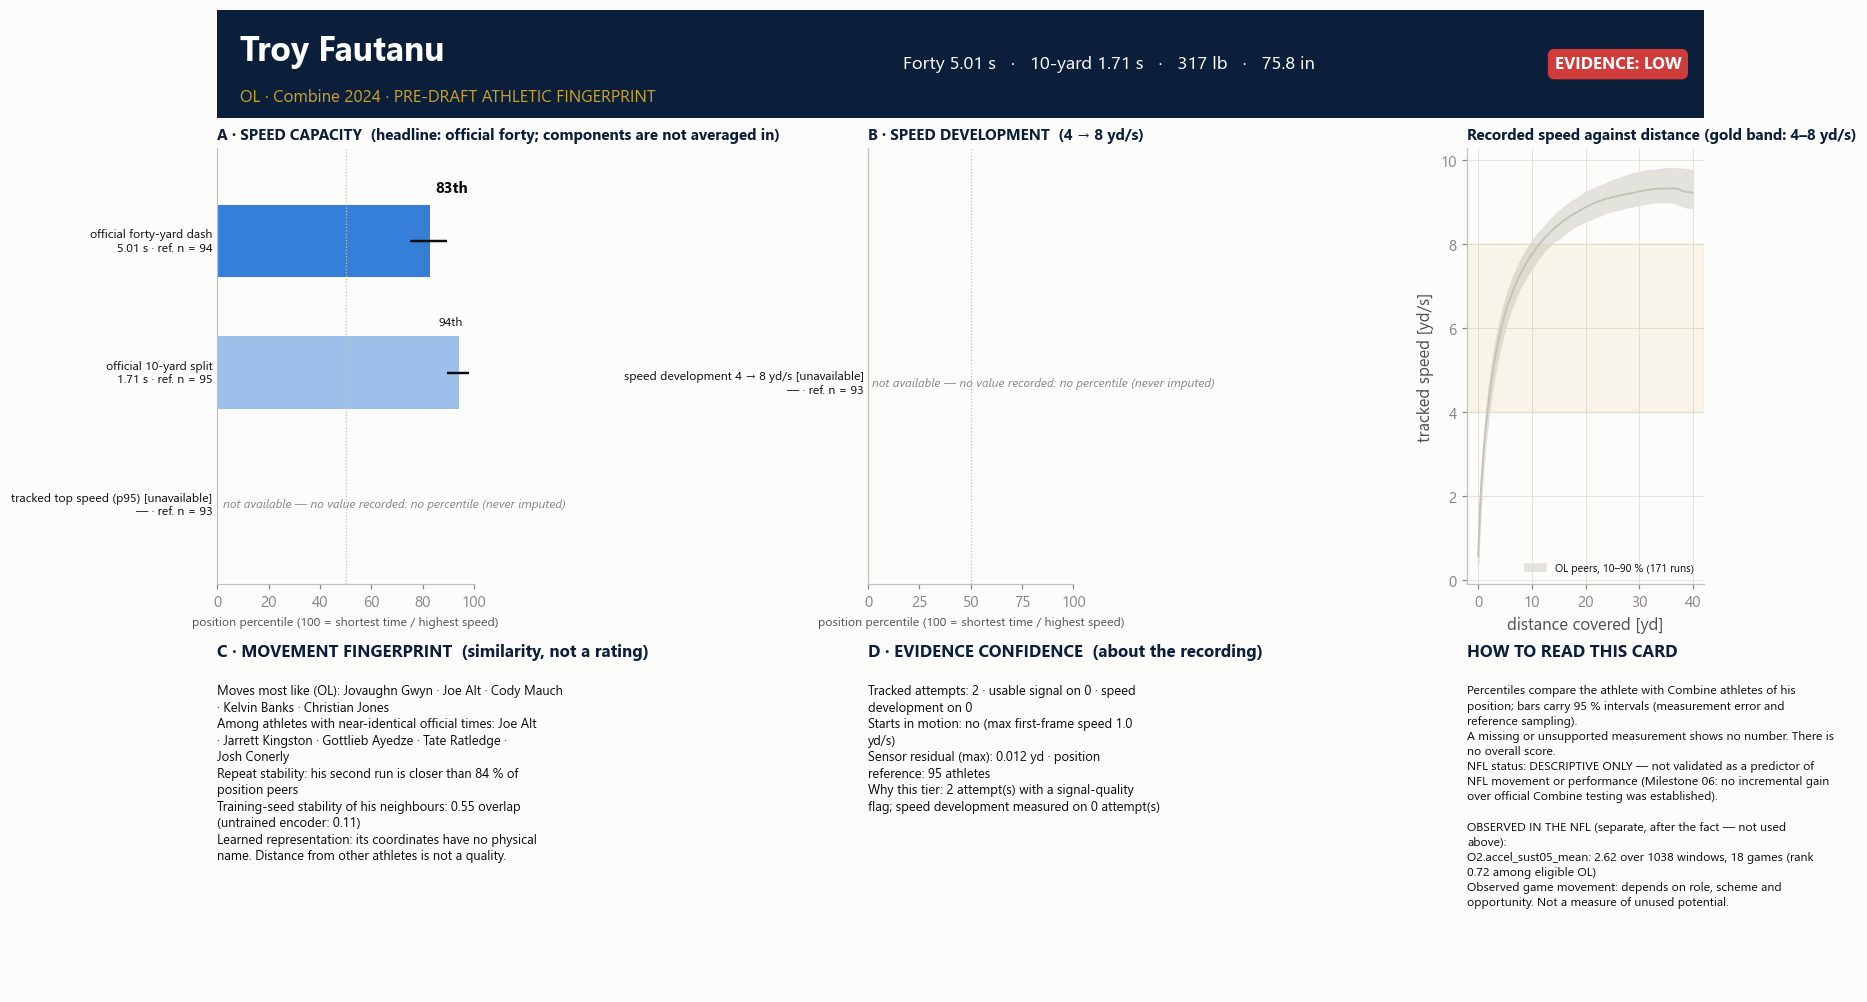

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\data\reporting.py:100: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(path, **kwargs)


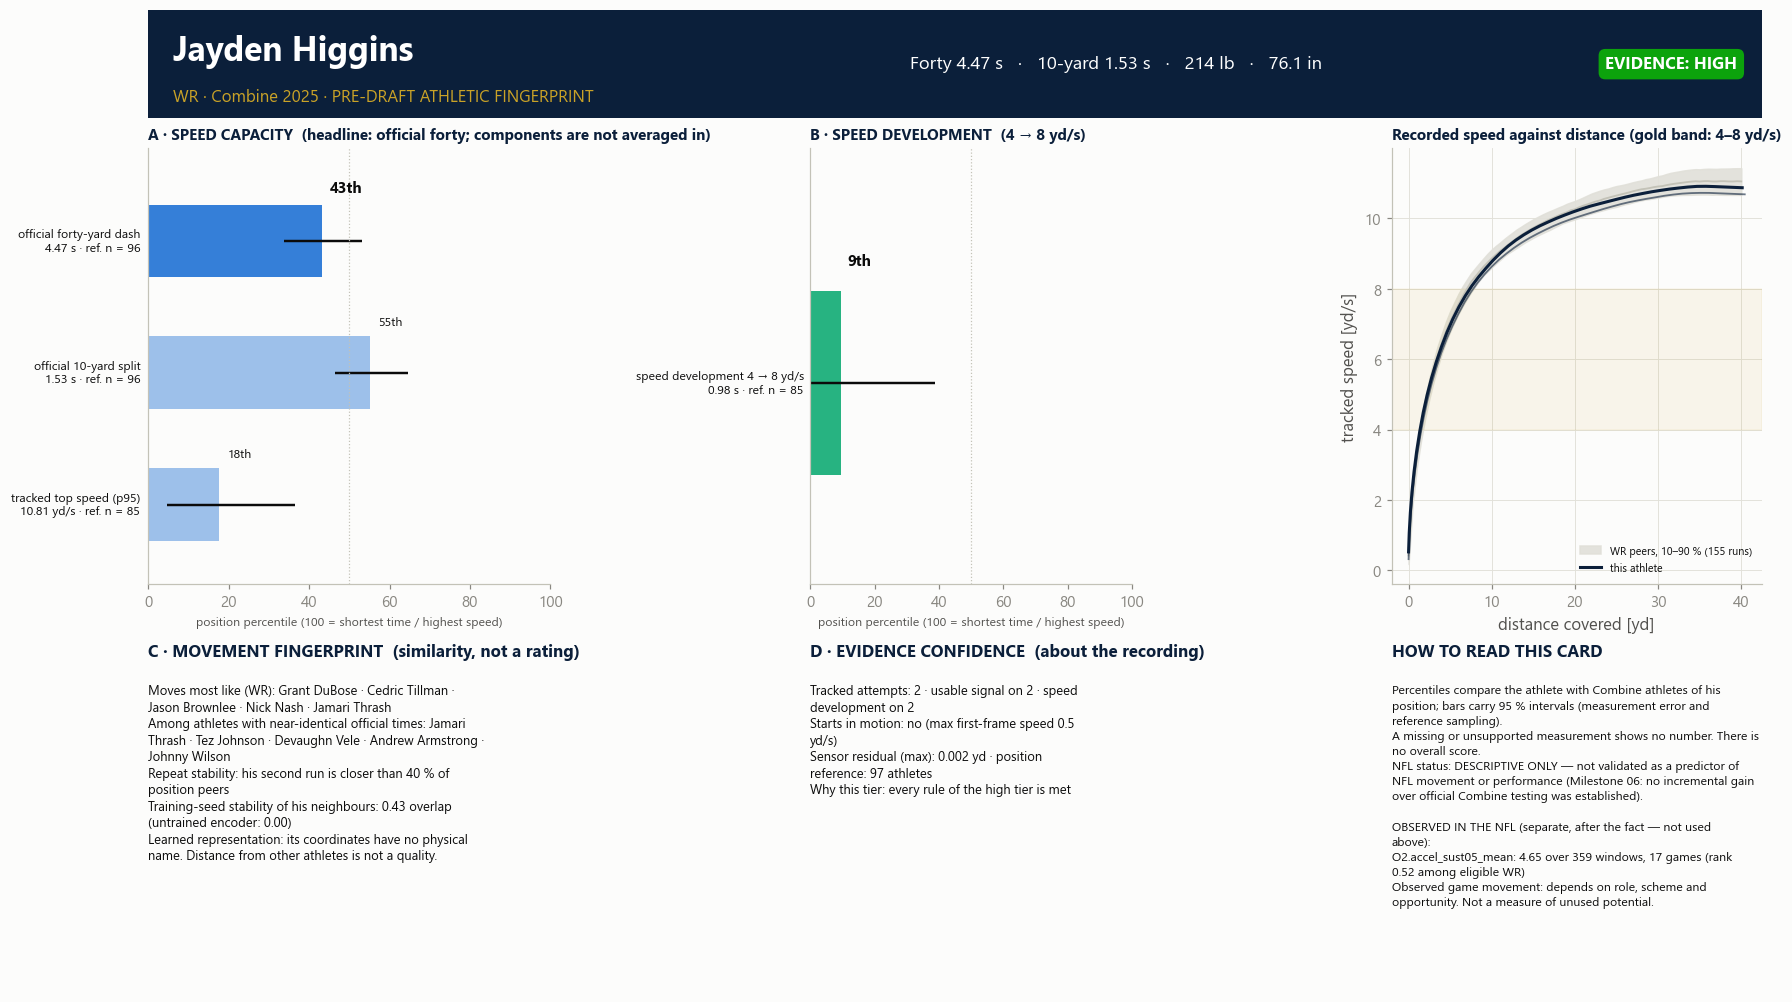

In [8]:
if PROFILE_ATHLETES == 'auto':
    first = examples.unique(subset=['case'], keep='first', maintain_order=True)
    CARD_IDS = list(dict.fromkeys([*first['nfl_id_a'].to_list(), *first['nfl_id_b'].to_list()]))[:6]
    if not CARD_IDS:
        CARD_IDS = profile.filter(pl.col('evidence_tier') == 'high')['nfl_id'].head(3).to_list()
else:
    CARD_IDS = [int(i) for i in PROFILE_ATHLETES]

NFL_PANEL = {}
if SHOW_NFL_PANEL and store.context.exists(co.ADJUSTED):          # post-draft, descriptive, separate — never joined to a pre-draft table
    post = store.context.read(co.ADJUSTED).filter(pl.col('nfl_id').is_in(CARD_IDS) & (pl.col('definition') == 'C0'))
    for r in post.iter_rows(named=True):
        NFL_PANEL[r['nfl_id']] = [f'{r["outcome_id"]}: {r["value"]:.2f} over {r["n_windows"]} windows, {r["n_games"]} games'
                                  + ('' if r['rank_in_position'] is None else f' (rank {r["rank_in_position"]:.2f} among eligible {r["position_group"]})'),
                                  'Observed game movement: depends on role, scheme and opportunity. Not a measure of unused potential.']

conf_by, stab_by, prof_by = ({r['nfl_id']: r for r in t.iter_rows(named=True)} for t in (confidence, stability, profile))
for i in CARD_IDS:
    if i not in prof_by:
        print(f'athlete {i}: not in the roster of {list(POSITION_GROUPS)} — no card')
        continue
    p = prof_by[i]
    band = BANDS.get(p['position_group'], sf.curve_band(frames, []))
    fig = sf.plot_scorecard(p, pct.filter(pl.col('nfl_id') == i), conf_by.get(i, {}), stab_by.get(i), band, curves_of(i), NFL_PANEL.get(i))
    store.show(fig, f'AM07D_01_scorecard_{i}', {'percentiles': pct.filter(pl.col('nfl_id') == i)}, publication=True,
               source='combine scorecard tables', n=f'1 athlete; position reference {p["reference_n"]} athletes', note=NFL_PREDICTIVE_STATUS)

## 6. Reference manifest and gate 07D

Gate 07D: scores have defined meanings · reference populations are known · position-specific uncertainty is reported · unsupported characteristics abstain · TCN coordinates are not named as physical traits · no NFL outcome is used in pre-draft scoring.

In [9]:
manifest = sc.reference_manifest(ref, reference_tables, pct, QUALITY_RULE,
                                 {'athlete_registry': '00', 'sequence_window_flags': '02', 'sequence_frames': '01', 'atlas_attempt_features': '04A',
                                  'transfer_attempt_representations_outer': '06B (fold encoders; none trained here)', 'seed_replicates': SEED_REPLICATES,
                                  'nfl_inputs': 'none'}, pc.REDUNDANCY_POLICY)
gate = sc.gate_07d(pct, profile, confidence, neighbors, examples, manifest, cr.GATE)
with pl.Config(tbl_rows=-1, fmt_str_lengths=400):
    display(gate)
GATE_07D = 'PASS' if gate['passed'].all() else 'FAIL'
shown = pct.filter(pl.col('percentile').is_not_null())
display(Markdown(f'**Gate 07D: {GATE_07D}** · {profile.height} profiles · {shown.height} percentiles shown, {pct.height - shown.height} withheld · '
                 f'{examples.height} case pairs · {len(CARD_IDS)} cards · overall score: none'))
if controls.save_tables:
    store.write_json('combine_score_reference_manifest', {**manifest, 'gate_07d': GATE_07D, 'experiment_version': EXPERIMENT_VERSION, 'seed': controls.seed,
                                                          'n_profiles': profile.height, 'card_athletes': CARD_IDS,
                                                          'evidence_tiers': dict(zip(*confidence.group_by('evidence_tier').agg(pl.len().alias('n')).select('evidence_tier', 'n'))),
                                                          'validation': dict(zip(validation['check'], validation['status'])), 'status': 'executed'})
cr.assert_gate(gate, '07D')

criterion,passed,detail
str,bool,str
"""scores_have_defined_meanings""",true,"""every percentile has a definition, a unit and an orientation in the manifest"""
"""reference_populations_known""",true,"""20 feature × position reference sets recorded"""
"""position_specific_uncertainty_reported""",true,"""1651 percentile(s) shown, each with an interval"""
"""unsupported_characteristics_abstain""",true,"""389 missing value(s) and 389 unavailable row(s) carry no percentile"""
"""tcn_coordinates_not_named_as_traits""",true,"""no latent coordinate, ability label or overall score in the profile"""
"""no_nfl_outcome_in_pre_draft_scoring""",true,"""no NFL-named column in any pre-draft table; no case selected with an NFL outcome"""


**Gate 07D: PASS** · 510 profiles · 1651 percentiles shown, 389 withheld · 10 case pairs · 6 cards · overall score: none

### What to send back

The validation table; the reference, availability, cohort-sensitivity and isolation tables (section 1); the fingerprint summary (section 2); the tier pivot and the quality table (section 3); the case table (section 4); the gate (section 6); figures `AM07D_01_*` (cards), `AM07D_02_*_01_*`, `AM07D_03`, `AM07D_04`, `AM07D_05_time_v4_to_v8_s`, `AM07D_06`; any traceback.

**Then:** fill `reports/FOOTBALL_CONTEXT_TRANSFER_AND_SCORING_RESULTS.md` from the persisted tables of 07A–07D. Milestone 07 ends here.